# File takes a look at the common sequences of instructions found across the 5 programs and determines the similairy based on graphical represention.

In [1]:
from matplotlib import pyplot as plt
import random
import tensorflow as tf
import numpy as np
import timeit
import scipy.io as sio
import csv
import os
import math 
import random as rand
from numpy import genfromtxt
from numpy import sum,isrealobj,sqrt
from numpy.random import standard_normal
from keras.models import load_model

import warnings
from scipy.signal import savgol_filter
from scipy.spatial import distance

from Modules.Tools import MapTool
from Modules.Tools import csv2Numpy
from Modules.Tools import BoxPlot
from Modules.Tools import peakCorrelation as pC

In [2]:
# Signal 
params = {'legend.fontsize': 50,
          'figure.figsize': (45, 15),
         'axes.labelsize': 60,
         'axes.titlesize':70,
         'xtick.labelsize':50,
         'ytick.labelsize':50,
         'lines.linewidth': 8}
plt.rcParams.update(params)

In [3]:
save_folder = "./Graphs/1_1_Analyzing Common Sequences/"
load_folder = "./Datasets/Numpy/FP_GANs_LargeScale_2/segment/"
pad = 8
y_low=-2.8
y_high=2.8
amount=1500

In [4]:
def getValue(dataset, loc):
    list_peaks = []
    
    for peaks in dataset:
        list_peaks.append(peaks[loc])
    return np.array(list_peaks)

# Load Datasets

In [6]:
Alpha = np.load(load_folder + "Alpha/Alpha_segment.npy", allow_pickle=True)
Bravo = np.load(load_folder + "Bravo/Bravo_segment.npy", allow_pickle=True)
Charlie = np.load(load_folder + "Charlie/Charlie_segment.npy", allow_pickle=True)
Delta = np.load(load_folder + "Delta/Delta_segment.npy", allow_pickle=True)
Echo = np.load(load_folder + "Echo/Echo_segment.npy", allow_pickle=True)

In [7]:
sub = np.load("./Datasets/Numpy/sub_full.npy", allow_pickle=True)

# Graph Signals and locate sequences

In [8]:
test_loc = 100

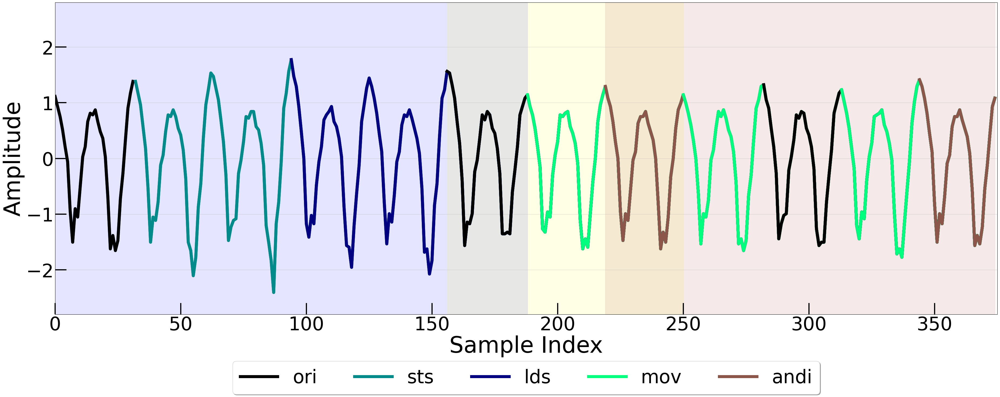

In [9]:
code = ["ori", "sts", "lds", "ori", "mov",
        "andi", "mov", "ori", "mov", "andi"]

Signal = Alpha[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 0), MapTool.getPeaksLoc(Signal, pad, 12), color='blue', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 16), color='yellow', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 14), MapTool.getPeaksLoc(Signal, pad, 24), color='brown', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Alpha_segment.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

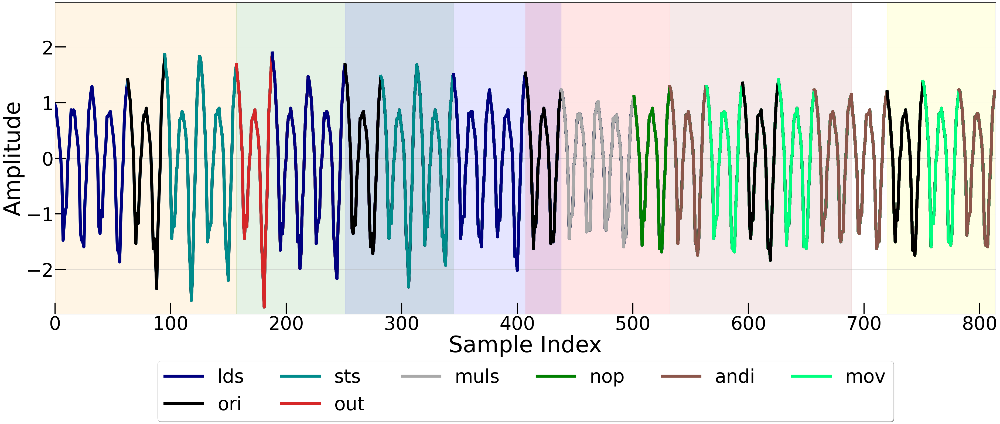

In [10]:
code = ["lds", "ori", "sts", "out", "lds",
        "ori", "sts", "lds", "ori", "muls",
        "nop", "andi", "mov", "ori", "mov",
        "andi", "andi", "ori", "mov", "andi"]

Signal = Bravo[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 0), MapTool.getPeaksLoc(Signal, pad, 10), color='orange', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 22), color='green', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 16), MapTool.getPeaksLoc(Signal, pad, 28), color='blue', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 26), MapTool.getPeaksLoc(Signal, pad, 34), color='red', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 34), MapTool.getPeaksLoc(Signal, pad, 44), color='brown', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 46), MapTool.getPeaksLoc(Signal, pad, 52), color='yellow', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Bravo_segment.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

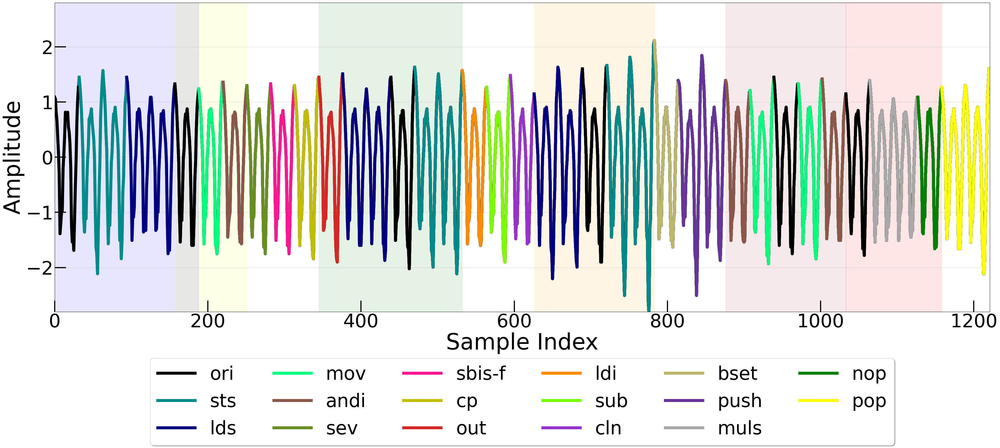

In [11]:
code = ["ori", "sts", "lds", "ori", "mov",
              "andi", "sev", "sbis-f", "cp", "out",
              "lds", "ori", "sts", "ldi", "sub",
              "cln", "lds", "ori", "sts", "bset",
              "push", "andi", "mov", "ori", "mov",
              "andi", "ori", "muls", "nop", "pop"]

Signal = Charlie[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 0), MapTool.getPeaksLoc(Signal, pad, 12), color='blue', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 16), color='yellow', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 34), color='green', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 50), color='orange', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 56), MapTool.getPeaksLoc(Signal, pad, 66), color='brown', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 66), MapTool.getPeaksLoc(Signal, pad, 74), color='red', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Charlie_segment.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

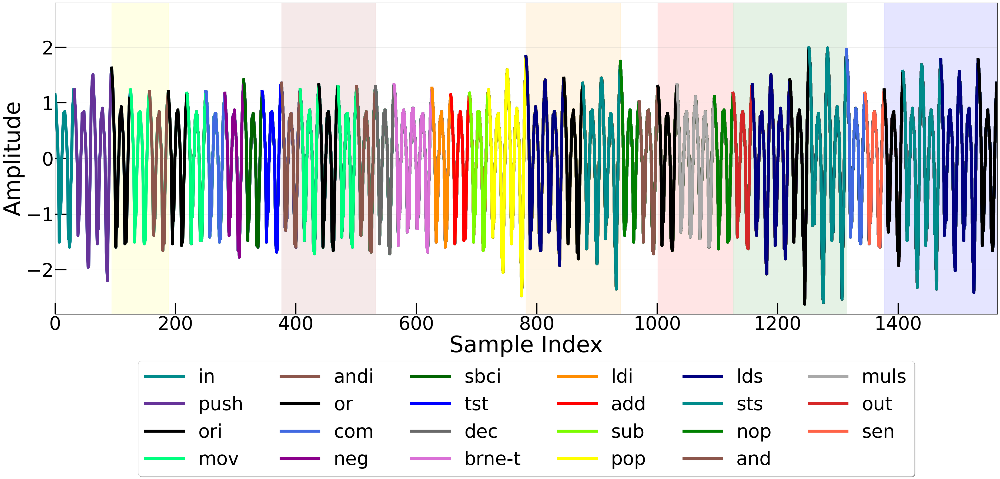

In [12]:
code = ["in", "push", "ori", "mov", "andi",
              "or", "mov", "com", "neg", "sbci",
              "tst", "andi", "mov", "ori", "mov",
              "andi", "dec", "brne-t", "ldi", "add",
              "sub", "pop", "lds", "ori", "sts",
              "nop", "and", "ori", "muls", "nop",
              "out", "lds", "ori", "sts", "com",
              "sen", "ori", "sts", "lds", "ori"]

Signal = Delta[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 6), MapTool.getPeaksLoc(Signal, pad, 12), color='yellow', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 24), MapTool.getPeaksLoc(Signal, pad, 34), color='brown', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 50), MapTool.getPeaksLoc(Signal, pad, 60), color='orange', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 64), MapTool.getPeaksLoc(Signal, pad, 72), color='red', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 72), MapTool.getPeaksLoc(Signal, pad, 84), color='green', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 88), MapTool.getPeaksLoc(Signal, pad, 100), color='blue', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Delta_segment.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

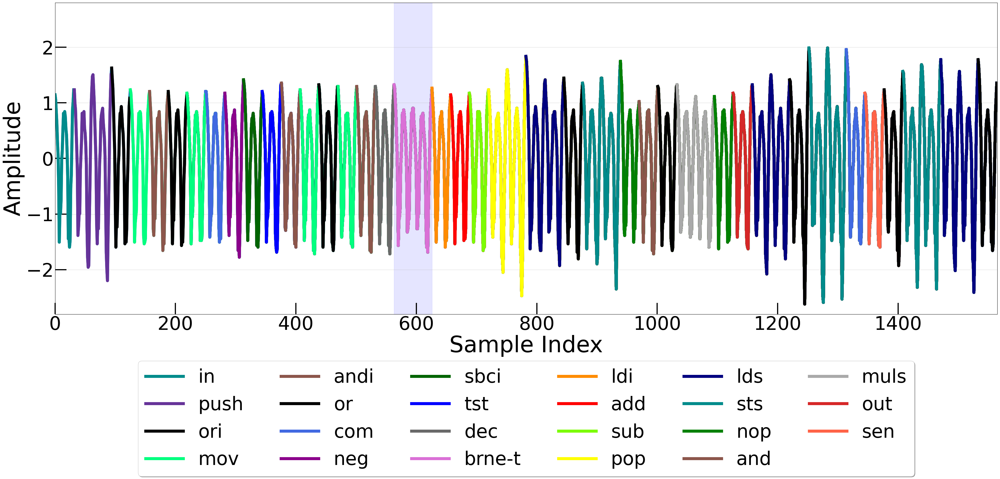

In [13]:
code = ["in", "push", "ori", "mov", "andi",
              "or", "mov", "com", "neg", "sbci",
              "tst", "andi", "mov", "ori", "mov",
              "andi", "dec", "brne-t", "ldi", "add",
              "sub", "pop", "lds", "ori", "sts",
              "nop", "and", "ori", "muls", "nop",
              "out", "lds", "ori", "sts", "com",
              "sen", "ori", "sts", "lds", "ori"]

Signal = Delta[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 36), MapTool.getPeaksLoc(Signal, pad, 40), color='blue', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Delta_segment-HL_Branch.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

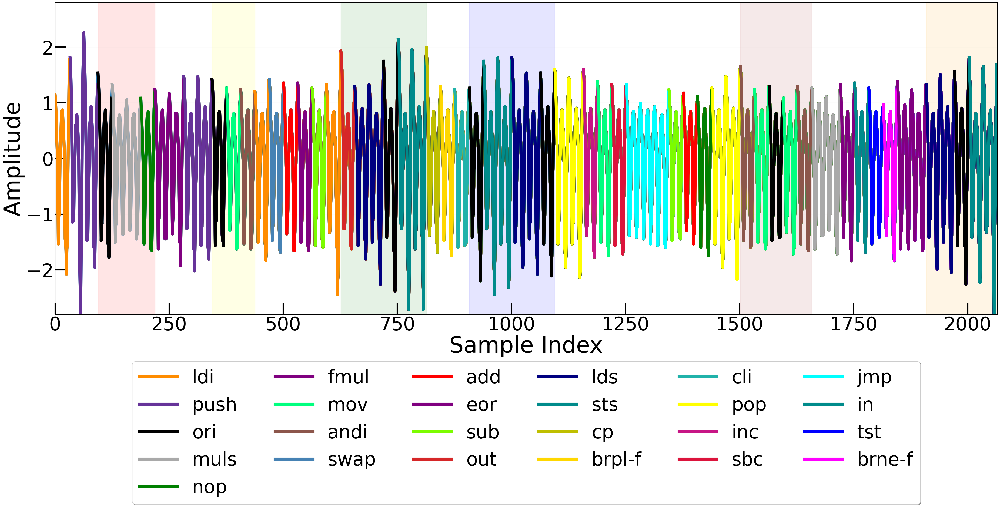

In [14]:
code = ["ldi", "push", "ori", "muls", "nop",
              "fmul", "push", "ori", "mov", "andi",
              "ldi", "swap", "add", "eor", "sub",
              "ldi", "out", "lds", "ori", "sts",
              "cp", "brpl-f", "cli", "ori", "sts",
              "lds", "ori", "pop", "inc", "mov",
              "sbc", "jmp", "sub", "add", "nop",
              "pop", "andi", "mov", "ori", "mov",
              "andi", "muls", "eor", "in", "tst",
              "brne-f", "fmul", "lds", "ori", "sts"]

Signal = Echo[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 6), MapTool.getPeaksLoc(Signal, pad, 14), color='red', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 28), color='yellow', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 52), color='green', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 58), MapTool.getPeaksLoc(Signal, pad, 70), color='blue', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 96), MapTool.getPeaksLoc(Signal, pad, 106), color='brown', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 122), MapTool.getPeaksLoc(Signal, pad, 132), color='orange', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Echo_segment.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

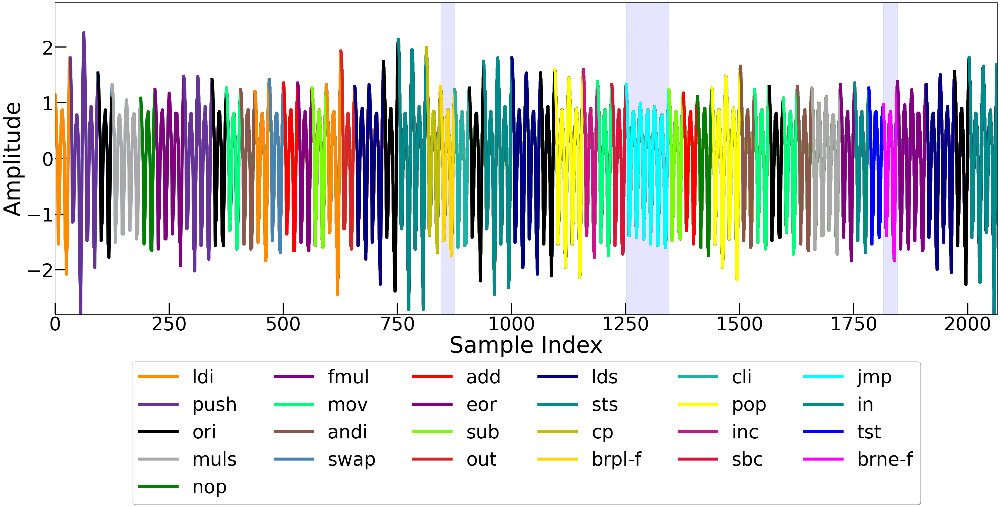

In [15]:
code = ["ldi", "push", "ori", "muls", "nop",
              "fmul", "push", "ori", "mov", "andi",
              "ldi", "swap", "add", "eor", "sub",
              "ldi", "out", "lds", "ori", "sts",
              "cp", "brpl-f", "cli", "ori", "sts",
              "lds", "ori", "pop", "inc", "mov",
              "sbc", "jmp", "sub", "add", "nop",
              "pop", "andi", "mov", "ori", "mov",
              "andi", "muls", "eor", "in", "tst",
              "brne-f", "fmul", "lds", "ori", "sts"]

Signal = Echo[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 54), MapTool.getPeaksLoc(Signal, pad, 56), color='blue', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 80), MapTool.getPeaksLoc(Signal, pad, 86), color='blue', alpha=0.1)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 116), MapTool.getPeaksLoc(Signal, pad, 118), color='blue', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Echo_segment-HL_Branch.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

# Obtain LDI samples from programs

In [77]:
# Signal 
params = {'legend.fontsize': 50,
          'figure.figsize': (60, 15),
         'axes.labelsize': 60,
         'axes.titlesize':70,
         'xtick.labelsize':50,
         'ytick.labelsize':50,
         'lines.linewidth': 8}
plt.rcParams.update(params)

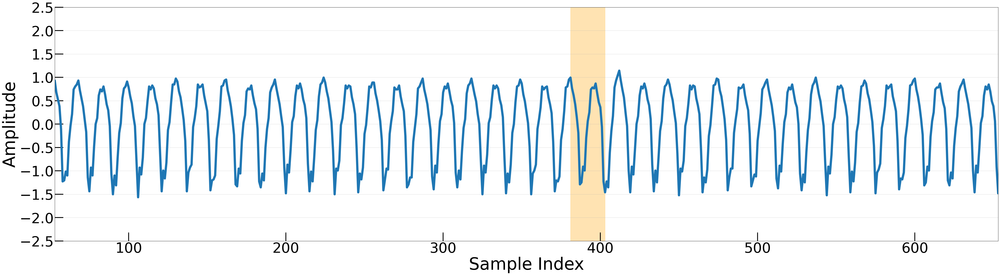

In [78]:
code = ["nop", "nop", "nop", "nop", "nop", 
              "nop", "nop", "nop", "nop", "nop",
             "nop", "nop",
        "ldi",
        "nop", "nop", "nop", "nop", "nop", 
            "nop", "nop", "nop", "nop", "nop",
            "nop", "nop",
            "clr", "clr", "clr", "clr", "clr",
            "clr", "clr",
            "clc", "cln", "clz", "cli", "cls",
            "clv", "clt", "clh", 
            "rjmp", "sbi"]
test_loc = 100
Signal = ldi[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 24), MapTool.getPeaksLoc(Signal, pad, 26, False), color='orange', alpha=0.3)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 16), color='yellow', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 34), color='green', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 50), color='orange', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 56), MapTool.getPeaksLoc(Signal, pad, 66), color='brown', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 66), MapTool.getPeaksLoc(Signal, pad, 74), color='red', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([53,653])
plt.ylim(-2.5, 2.5)
plt.yticks(ticks=np.arange(-2.5, 3, 0.5))
plt.savefig("./Graphs_Nops_ldi.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

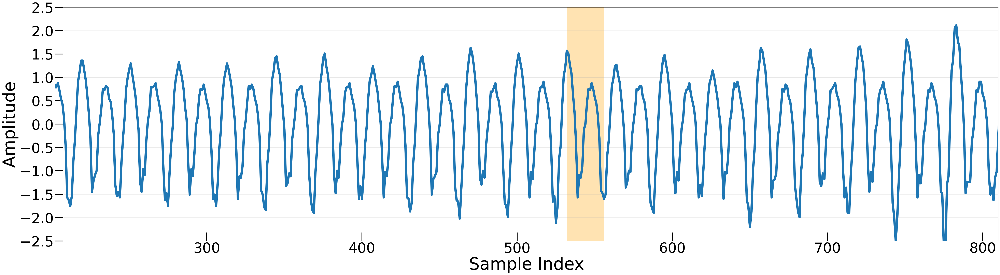

In [79]:
code = ["ori", "sts", "lds", "ori", "mov",
              "andi", "sev", "sbis-f", "cp", "out",
              "lds", "ori", "sts", "ldi", "sub",
              "cln", "lds", "ori", "sts", "bset",
              "push", "andi", "mov", "ori", "mov",
              "andi", "ori", "muls", "nop", "pop"]
test_loc = 100
Signal = Charlie[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 34), MapTool.getPeaksLoc(Signal, pad, 35, False), color='orange', alpha=0.3)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 16), color='yellow', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 34), color='green', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 50), color='orange', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 56), MapTool.getPeaksLoc(Signal, pad, 66), color='brown', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 66), MapTool.getPeaksLoc(Signal, pad, 74), color='red', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([202,810])
plt.ylim(-2.5, 2.5)
plt.yticks(ticks=np.arange(-2.5, 3, 0.5))
plt.savefig("./Graphs_Charlie_ldi.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

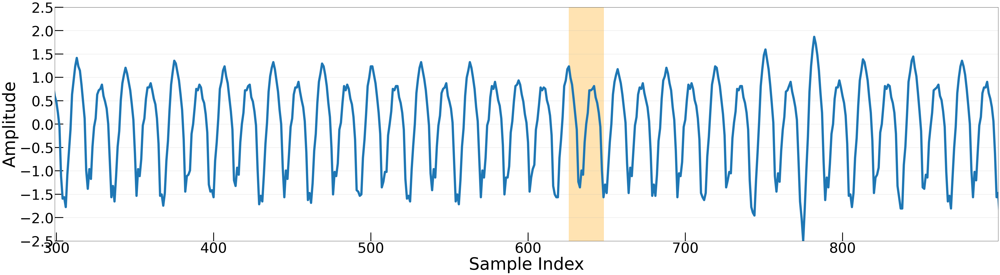

In [80]:
code = ["in", "push", "ori", "mov", "andi",
              "or", "mov", "com", "neg", "sbci",
              "tst", "andi", "mov", "ori", "mov",
              "andi", "dec", "brne-t", "ldi", "add",
              "sub", "pop", "lds", "ori", "sts",
              "nop", "and", "ori", "muls", "nop",
              "out", "lds", "ori", "sts", "com",
              "sen", "ori", "sts", "lds", "ori"]
test_loc = 1
Signal = Delta[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 41,False), color='orange', alpha=0.3)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 24), MapTool.getPeaksLoc(Signal, pad, 34), color='brown', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 50), MapTool.getPeaksLoc(Signal, pad, 60), color='orange', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 64), MapTool.getPeaksLoc(Signal, pad, 72), color='red', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 72), MapTool.getPeaksLoc(Signal, pad, 84), color='green', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 88), MapTool.getPeaksLoc(Signal, pad, 100), color='blue', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([299,899])
plt.ylim(-2.5, 2.5)
plt.yticks(ticks=np.arange(-2.5, 3, 0.5))
plt.savefig("./Graphs_Delta_ldi.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

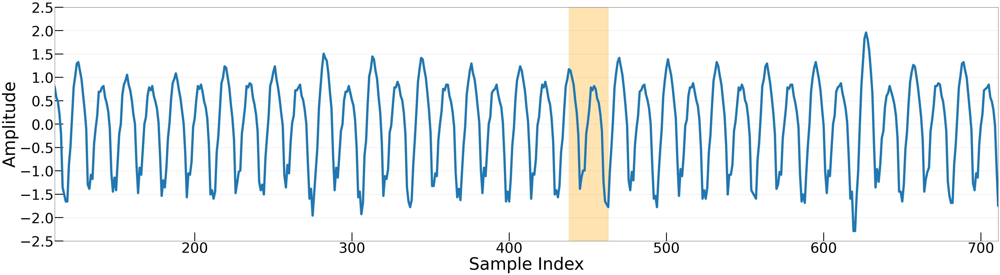

In [81]:
code = ["ldi", "push", "ori", "muls", "nop",
              "fmul", "push", "ori", "mov", "andi",
              "ldi", "swap", "add", "eor", "sub",
              "ldi", "out", "lds", "ori", "sts",
              "cp", "brpl-f", "cli", "ori", "sts",
              "lds", "ori", "pop", "inc", "mov",
              "sbc", "jmp", "sub", "add", "nop",
              "pop", "andi", "mov", "ori", "mov",
              "andi", "muls", "eor", "in", "tst",
              "brne-f", "fmul", "lds", "ori", "sts"]
test_loc = 1
Signal = Echo[1]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 28), MapTool.getPeaksLoc(Signal, pad, 29, False), color='orange', alpha=0.3)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 28), color='yellow', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 52), color='green', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 58), MapTool.getPeaksLoc(Signal, pad, 70), color='blue', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 96), MapTool.getPeaksLoc(Signal, pad, 106), color='brown', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 122), MapTool.getPeaksLoc(Signal, pad, 132), color='orange', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([111,711])
plt.ylim(-2.5, 2.5)
plt.yticks(ticks=np.arange(-2.5, 3, 0.5))
plt.savefig("./Graphs_Echo_ldi.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

In [86]:
# Signal 
params = {'legend.fontsize': 50,
          'figure.figsize': (10, 15),
         'axes.labelsize': 60,
         'axes.titlesize':70,
         'xtick.labelsize':50,
         'ytick.labelsize':50,
         'lines.linewidth': 8}
plt.rcParams.update(params)

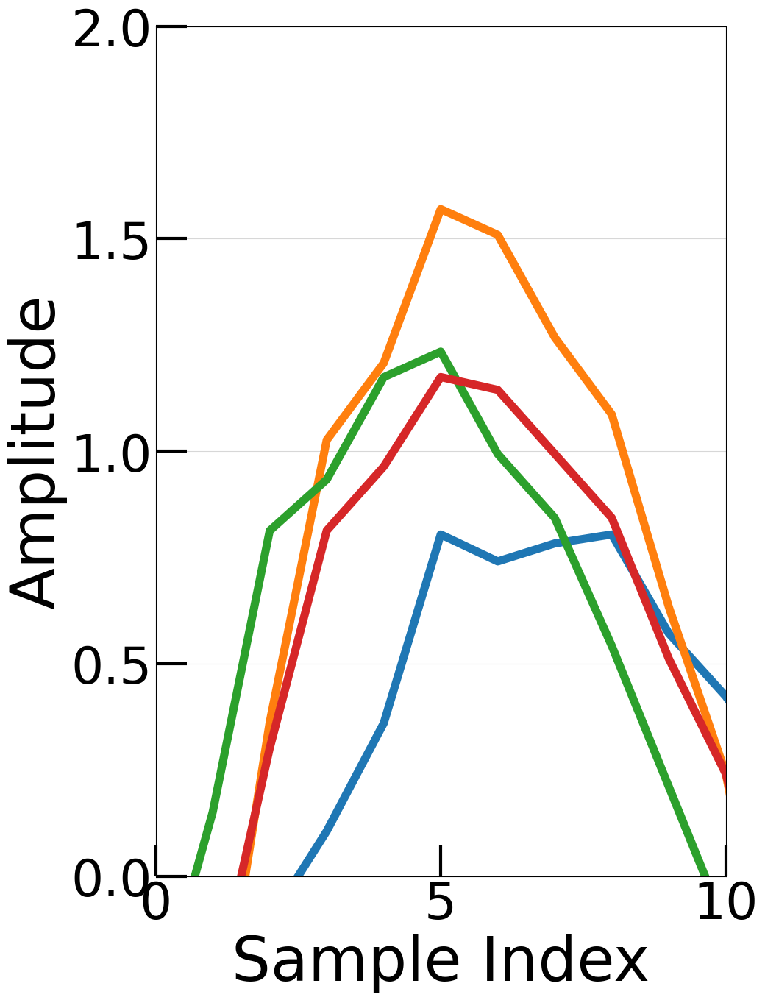

In [87]:
test_loc = 100
Signal = ldi[test_loc][MapTool.getPeaksLoc(ldi[test_loc], pad, 23, False)+2: MapTool.getPeaksLoc(ldi[test_loc], pad, 23, False) + 22]
time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)

test_loc = 100
Signal = Charlie[test_loc][MapTool.getPeaksLoc(Charlie[test_loc], pad, 33, False)+2: MapTool.getPeaksLoc(Charlie[test_loc], pad, 33, False) + 22]
time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)

test_loc = 1
Signal = Delta[test_loc][MapTool.getPeaksLoc(Delta[test_loc], pad, 39, False)+3: MapTool.getPeaksLoc(Delta[test_loc], pad, 39, False) + 22]
time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)

test_loc = 1
Signal = Echo[test_loc][MapTool.getPeaksLoc(Echo[test_loc], pad, 27, False)+2: MapTool.getPeaksLoc(Echo[test_loc], pad, 27, False) + 22]
time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,10])
plt.ylim(0, 2)
plt.yticks(ticks=np.arange(0, 2.5, 0.5))
plt.savefig("./Graphs_ldi_Zoom.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

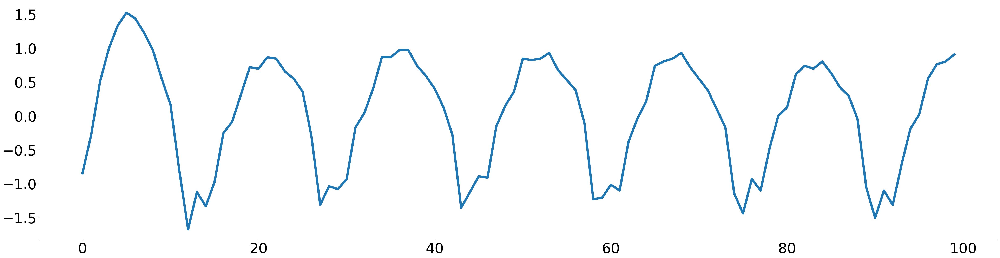

In [25]:
plt.plot(ldi[test_loc][0:100])

# Obtain example of a singal and just the peaks

In [100]:
params = {'legend.fontsize': 50,
          'figure.figsize': (70, 15),
         'axes.labelsize': 60,
         'axes.titlesize':70,
         'xtick.labelsize':50,
         'ytick.labelsize':50,
          'font.weight': "bold",
         'lines.linewidth': 5}
plt.rcParams.update(params)

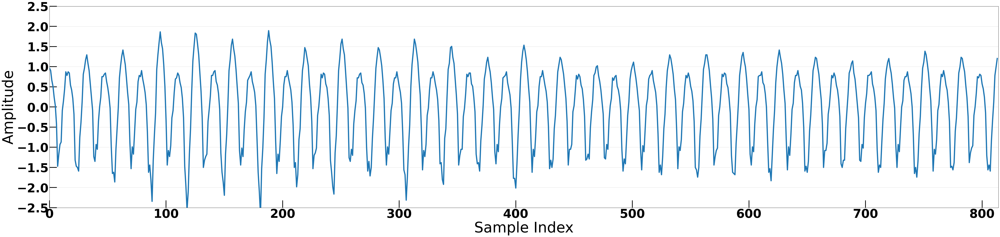

In [101]:

test_loc = 100
Signal = Bravo[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
#MapTool.mapCodeSignal(Signal, code, pad)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 34), MapTool.getPeaksLoc(Signal, pad, 35, False), color='orange', alpha=0.3)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 16), color='yellow', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 34), color='green', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 50), color='orange', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 56), MapTool.getPeaksLoc(Signal, pad, 66), color='brown', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 66), MapTool.getPeaksLoc(Signal, pad, 74), color='red', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(-2.5, 2.5)
plt.yticks(ticks=np.arange(-2.5, 3, 0.5))
plt.savefig("./Full_EM_Sample.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

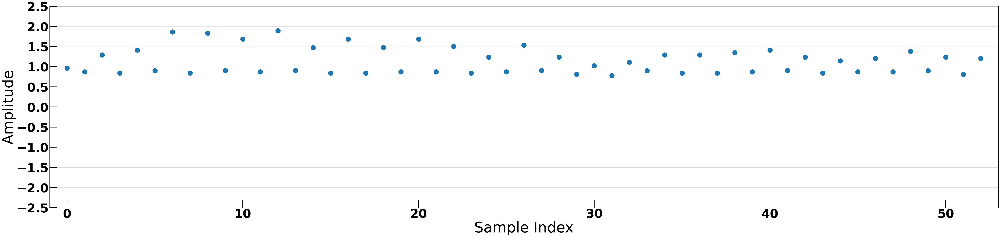

In [103]:
test_loc = 100
Signal = Bravo[test_loc]
Signal = MapTool.getPeaks(Signal, pad)

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal, "o", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 34), MapTool.getPeaksLoc(Signal, pad, 35, False), color='orange', alpha=0.3)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 16), color='yellow', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 34), color='green', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 50), color='orange', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 56), MapTool.getPeaksLoc(Signal, pad, 66), color='brown', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 66), MapTool.getPeaksLoc(Signal, pad, 74), color='red', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(Signal)])
plt.ylim(-2.5, 2.5)
plt.yticks(ticks=np.arange(-2.5, 3, 0.5))
plt.savefig("./Peaks_Sample.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

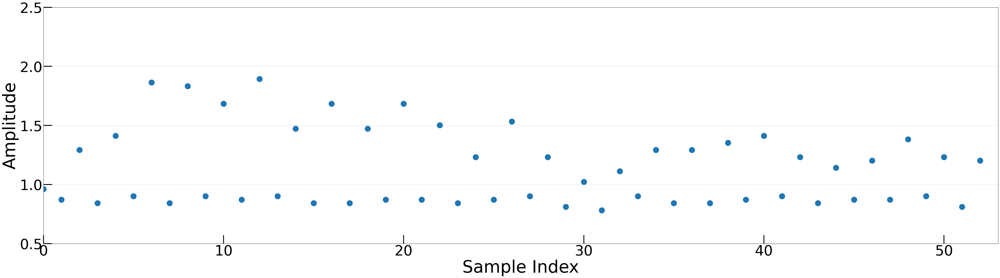

In [96]:

test_loc = 100
Signal = Bravo[test_loc]
Signal = MapTool.getPeaks(Signal, pad)

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal, "o", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 34), MapTool.getPeaksLoc(Signal, pad, 35, False), color='orange', alpha=0.3)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 10), MapTool.getPeaksLoc(Signal, pad, 16), color='yellow', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 22), MapTool.getPeaksLoc(Signal, pad, 34), color='green', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 40), MapTool.getPeaksLoc(Signal, pad, 50), color='orange', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 56), MapTool.getPeaksLoc(Signal, pad, 66), color='brown', alpha=0.1)
#plt.axvspan(MapTool.getPeaksLoc(Signal, pad, 66), MapTool.getPeaksLoc(Signal, pad, 74), color='red', alpha=0.1)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(0.5, 2.5)
plt.yticks(ticks=np.arange(0.5, 3, 0.5))
#plt.savefig("./Graphs_Charlie_ldi.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

# Signal of sequences

In [12]:
Alpha_Yellow = pC.getSeqSignals(Alpha, 10, 16, pad)
Bravo_Yellow = pC.getSeqSignals(Bravo, 46, 52, pad)
Charlie_Yellow = pC.getSeqSignals(Charlie, 10, 16, pad)
Delta_Yellow = pC.getSeqSignals(Delta, 6, 12, pad)
Echo_Yellow = pC.getSeqSignals(Echo, 22, 28, pad)

#Alpha_Red = pC.getSeqSignals(Alpha, start_peak, end_peak, pad)
Bravo_Red = pC.getSeqSignals(Bravo, 26, 34, pad)
Charlie_Red = pC.getSeqSignals(Charlie, 66, 74, pad)
Delta_Red = pC.getSeqSignals(Delta, 64, 72, pad)
Echo_Red = pC.getSeqSignals(Echo, 6, 14, pad)

#Alpha_Orange = pC.getSeqSignals(Alpha, start_peak, end_peak, pad)
Bravo_Orange = pC.getSeqSignals(Bravo, 0, 10, pad)
Charlie_Orange = pC.getSeqSignals(Charlie, 40, 50, pad)
Delta_Orange = pC.getSeqSignals(Delta, 50, 60, pad)
Echo_Orange = pC.getSeqSignals(Echo, 122, 132, pad)

#Alpha_Green = pC.getSeqSignals(Alpha, start_peak, end_peak, pad)
Bravo_Green = pC.getSeqSignals(Bravo, 10, 22, pad)
Charlie_Green = pC.getSeqSignals(Charlie, 22, 34, pad)
Delta_Green = pC.getSeqSignals(Delta, 72, 84, pad)
Echo_Green = pC.getSeqSignals(Echo, 40, 52, pad)

Alpha_Blue = pC.getSeqSignals(Alpha, 0, 12, pad)
Bravo_Blue = pC.getSeqSignals(Bravo, 16, 28, pad)
Charlie_Blue = pC.getSeqSignals(Charlie, 0, 12, pad)
Delta_Blue = pC.getSeqSignals(Delta, 88, 100, pad)
Echo_Blue = pC.getSeqSignals(Echo, 58, 70, pad)

Alpha_Brown = pC.getSeqSignals(Alpha, 14, 24, pad)
Bravo_Brown = pC.getSeqSignals(Bravo, 34, 44, pad)
Charlie_Brown = pC.getSeqSignals(Charlie, 56, 66, pad)
Delta_Brown = pC.getSeqSignals(Delta, 24, 34, pad)
Echo_Brown = pC.getSeqSignals(Echo, 96, 106, pad)

## Yellow

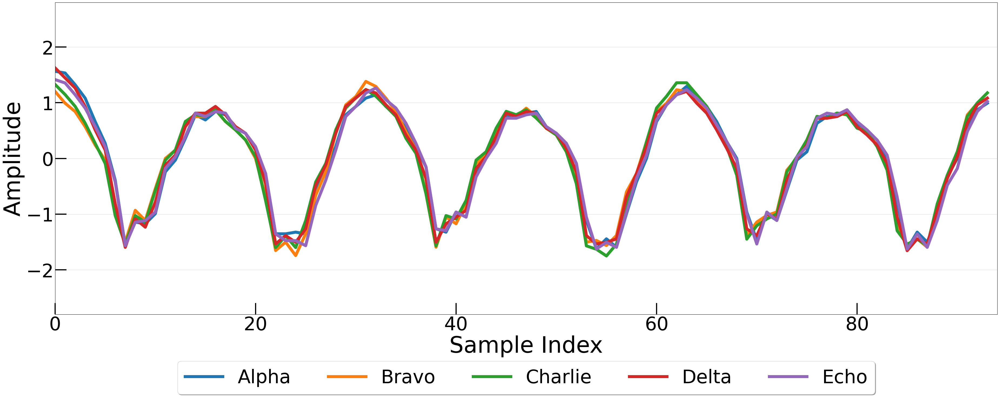

In [13]:
S_alpha = Alpha_Yellow[test_loc]
S_bravo = Bravo_Yellow[test_loc]
S_charlie = Charlie_Yellow[test_loc]
S_delta = Delta_Yellow[test_loc]
S_echo = Echo_Yellow[test_loc]

Shape = S_alpha.shape[0]
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
plt.plot(np.arange(S_alpha.shape[0]), S_alpha, label="Alpha")
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, label="Bravo")
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, label="Charlie")
plt.plot(np.arange(S_delta.shape[0]), S_delta, label="Delta")
plt.plot(np.arange(S_echo.shape[0]), S_echo, label="Echo")
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,Shape])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Yellow_Full.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

## Red

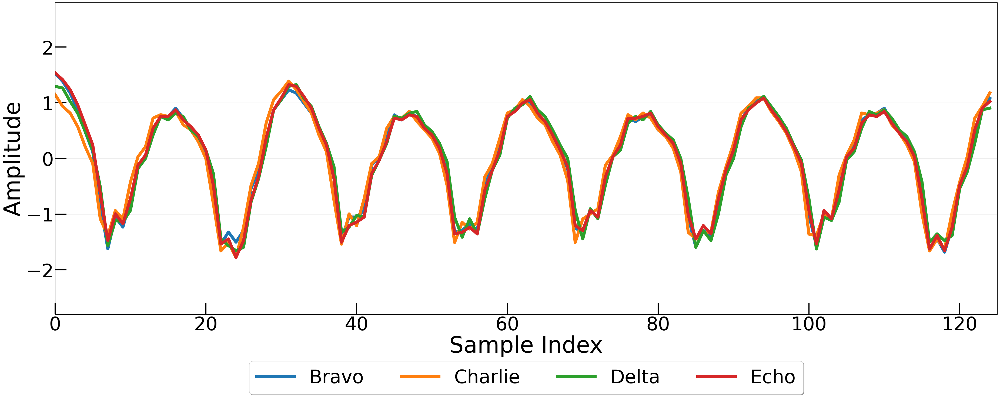

In [14]:
#S_alpha = Alpha_Red[test_loc]
S_bravo = Bravo_Red[test_loc]
S_charlie = Charlie_Red[test_loc]
S_delta = Delta_Red[test_loc]
S_echo = Echo_Red[test_loc]

Shape = 0
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
#plt.plot(np.arange(S_alpha.shape[0]), S_alpha, label="Alpha")
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, label="Bravo")
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, label="Charlie")
plt.plot(np.arange(S_delta.shape[0]), S_delta, label="Delta")
plt.plot(np.arange(S_echo.shape[0]), S_echo, label="Echo")
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,Shape])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Red_Full.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

## Orange

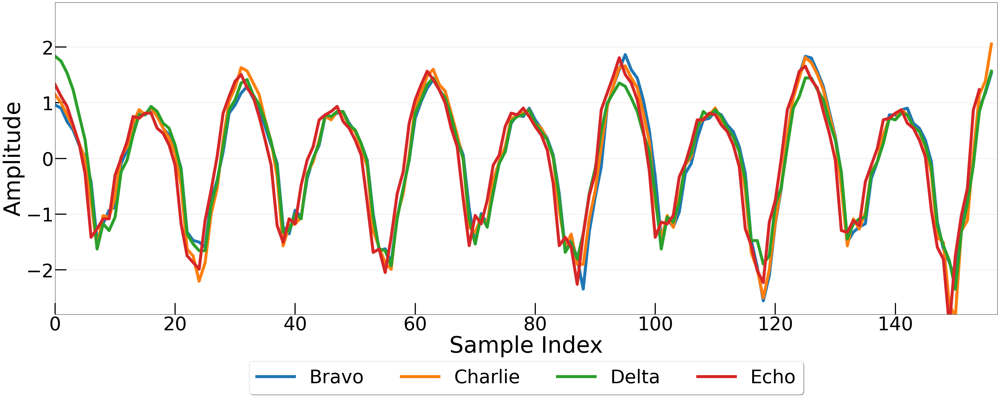

In [15]:
#S_alpha = Alpha_Orange[test_loc]
S_bravo = Bravo_Orange[test_loc]
S_charlie = Charlie_Orange[test_loc]
S_delta = Delta_Orange[test_loc]
S_echo = Echo_Orange[test_loc]

Shape = 0
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
#plt.plot(np.arange(S_alpha.shape[0]), S_alpha, label="Alpha")
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, label="Bravo")
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, label="Charlie")
plt.plot(np.arange(S_delta.shape[0]), S_delta, label="Delta")
plt.plot(np.arange(S_echo.shape[0]), S_echo, label="Echo")
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,Shape])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Orange_Full.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

## Green

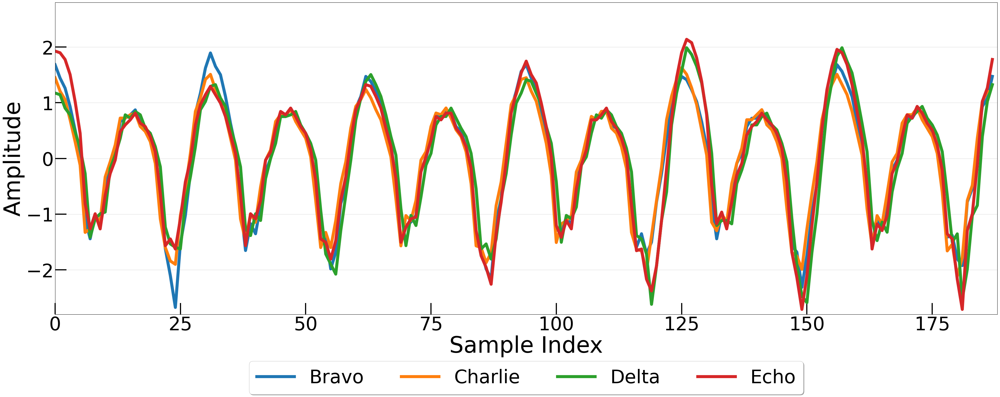

In [16]:
#S_alpha = Alpha_Green[test_loc]
S_bravo = Bravo_Green[test_loc]
S_charlie = Charlie_Green[test_loc]
S_delta = Delta_Green[test_loc]
S_echo = Echo_Green[test_loc]

Shape = 0
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
#plt.plot(np.arange(S_alpha.shape[0]), S_alpha, label="Alpha")
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, label="Bravo")
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, label="Charlie")
plt.plot(np.arange(S_delta.shape[0]), S_delta, label="Delta")
plt.plot(np.arange(S_echo.shape[0]), S_echo, label="Echo")
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,Shape])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Green_Full.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

## Blue

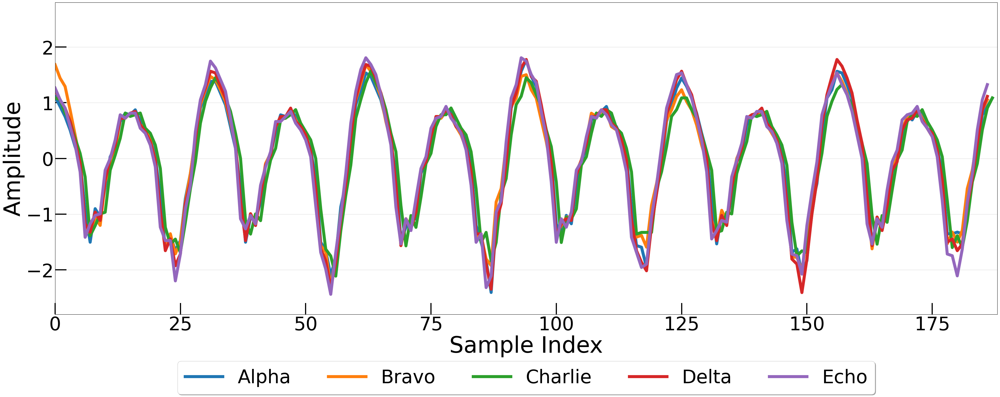

In [17]:
S_alpha = Alpha_Blue[test_loc]
S_bravo = Bravo_Blue[test_loc]
S_charlie = Charlie_Blue[test_loc]
S_delta = Delta_Blue[test_loc]
S_echo = Echo_Blue[test_loc]

Shape = S_alpha.shape[0]
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
plt.plot(np.arange(S_alpha.shape[0]), S_alpha, label="Alpha")
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, label="Bravo")
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, label="Charlie")
plt.plot(np.arange(S_delta.shape[0]), S_delta, label="Delta")
plt.plot(np.arange(S_echo.shape[0]), S_echo, label="Echo")
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,Shape])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Blue_Full.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

## Brown

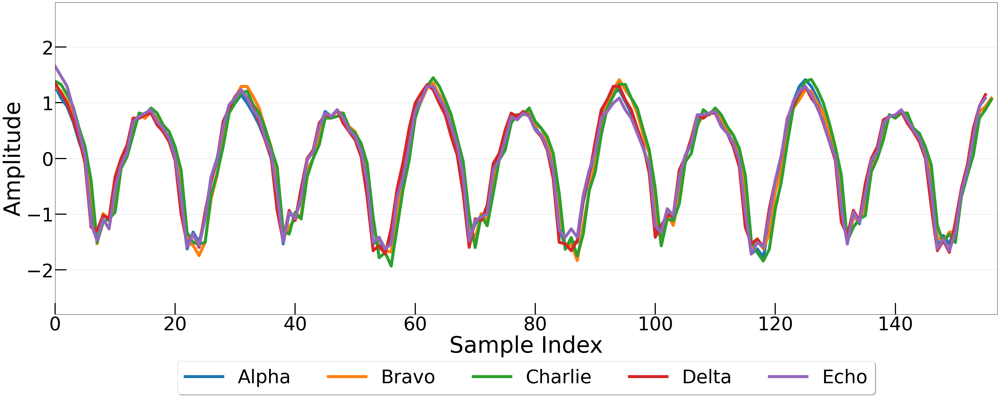

In [18]:
S_alpha = Alpha_Brown[test_loc]
S_bravo = Bravo_Brown[test_loc]
S_charlie = Charlie_Brown[test_loc]
S_delta = Delta_Brown[test_loc]
S_echo = Echo_Brown[test_loc]

Shape = S_alpha.shape[0]
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
plt.plot(np.arange(S_alpha.shape[0]), S_alpha, label="Alpha")
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, label="Bravo")
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, label="Charlie")
plt.plot(np.arange(S_delta.shape[0]), S_delta, label="Delta")
plt.plot(np.arange(S_echo.shape[0]), S_echo, label="Echo")
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,Shape])
plt.ylim(y_low,y_high)
plt.savefig(save_folder + "Brown_Full.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

# MP of sequences

In [19]:
'''
Extracts the major peaks, I.E. Every other peak.
'''
def extractMPs(dataset, pad):
    dataset_peaks = MapTool.getPeaksDataset(dataset, pad)
    
    new_Dataset = []
    for signal_peaks in dataset_peaks:
        signal_MPs = []
        peak_count = 0
        for peak in signal_peaks:
            if peak_count %2 == 0:
                signal_MPs.append(peak)
            peak_count = peak_count +1
        signal_MPs = signal_MPs[:len(signal_MPs)-1]
        new_Dataset.append(signal_MPs)
    
    return np.array(new_Dataset)

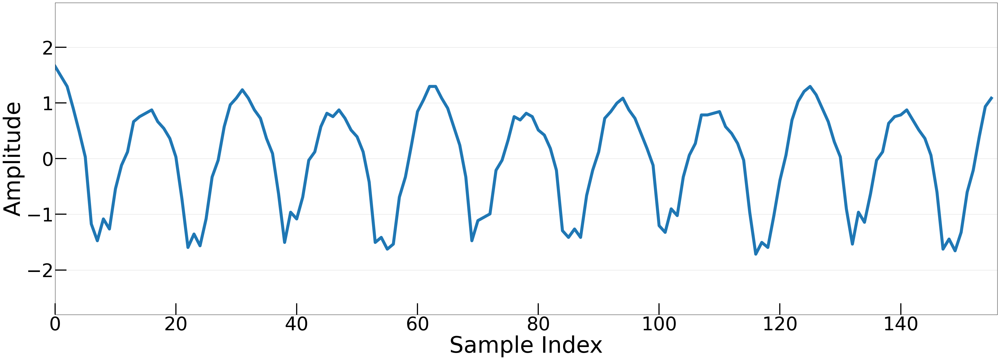

In [20]:
Signal = Echo_Brown[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([0,len(Signal)])
plt.ylim(y_low,y_high)
#plt.savefig(save_folder + "Echo_segment.png", bbox_inches='tight')
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.show()
plt.close()

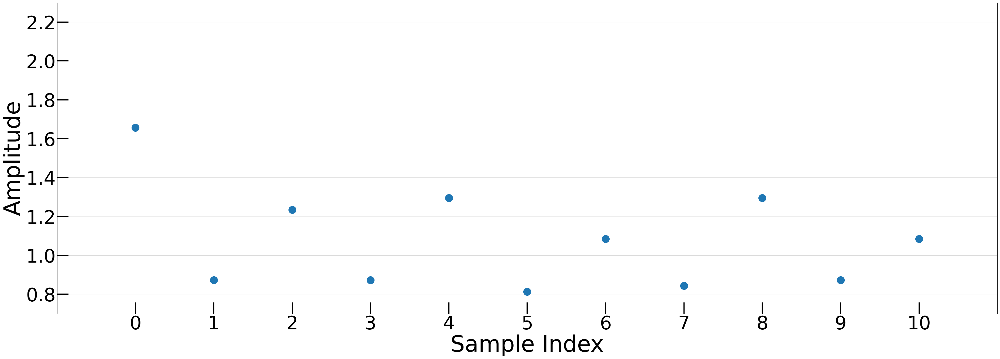

In [21]:
temp = MapTool.getPeaksDataset(Echo_Brown, pad)
Signal = temp[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal, "o", markersize=20)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(Signal)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(Signal)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
#plt.savefig(save_folder + "Signal_Compare_Real_4_Seq_Train_1200.png", bbox_inches='tight')
plt.show()
plt.close()

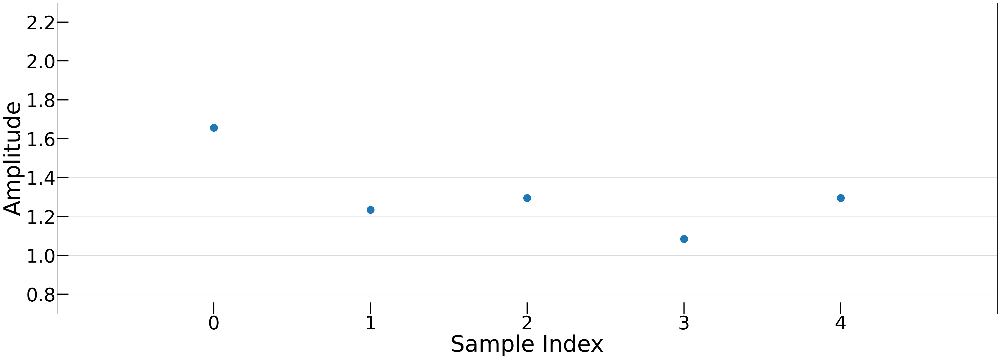

In [22]:
temp = extractMPs(Echo_Brown, pad)
Signal = temp[test_loc]

time_Signal = np.arange(Signal.shape[0])
plt.plot(time_Signal, Signal, "o", markersize=20)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

#plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
#          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(Signal)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(Signal)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
#plt.savefig(save_folder + "Signal_Compare_Real_4_Seq_Train_1200.png", bbox_inches='tight')
plt.show()
plt.close()

In [23]:
Alpha_Yellow_MP = extractMPs(Alpha_Yellow, pad)
Bravo_Yellow_MP = extractMPs(Bravo_Yellow, pad)
Charlie_Yellow_MP = extractMPs(Charlie_Yellow, pad)
Delta_Yellow_MP = extractMPs(Delta_Yellow, pad)
Echo_Yellow_MP = extractMPs(Echo_Yellow, pad)

#Alpha_Red_MP = extractMPs(Alpha_Red, pad)
Bravo_Red_MP = extractMPs(Bravo_Red, pad)
Charlie_Red_MP = extractMPs(Charlie_Red, pad)
Delta_Red_MP = extractMPs(Delta_Red, pad)
Echo_Red_MP = extractMPs(Echo_Red, pad)

#Alpha_Orange_MP = extractMPs(Alpha_Orange, pad)
Bravo_Orange_MP = extractMPs(Bravo_Orange, pad)
Charlie_Orange_MP = extractMPs(Charlie_Orange, pad)
Delta_Orange_MP = extractMPs(Delta_Orange, pad)
Echo_Orange_MP = extractMPs(Echo_Orange, pad)

#Alpha_Green_MP = extractMPs(Alpha_Green, pad)
Bravo_Green_MP = extractMPs(Bravo_Green, pad)
Charlie_Green_MP = extractMPs(Charlie_Green, pad)
Delta_Green_MP = extractMPs(Delta_Green, pad)
Echo_Green_MP = extractMPs(Echo_Green, pad)

Alpha_Blue_MP = extractMPs(Alpha_Blue, pad)
Bravo_Blue_MP = extractMPs(Bravo_Blue, pad)
Charlie_Blue_MP = extractMPs(Charlie_Blue, pad)
Delta_Blue_MP = extractMPs(Delta_Blue, pad)
Echo_Blue_MP = extractMPs(Echo_Blue, pad)

Alpha_Brown_MP = extractMPs(Alpha_Brown, pad)
Bravo_Brown_MP = extractMPs(Bravo_Brown, pad)
Charlie_Brown_MP = extractMPs(Charlie_Brown, pad)
Delta_Brown_MP = extractMPs(Delta_Brown, pad)
Echo_Brown_MP = extractMPs(Echo_Brown, pad)

## Yellow

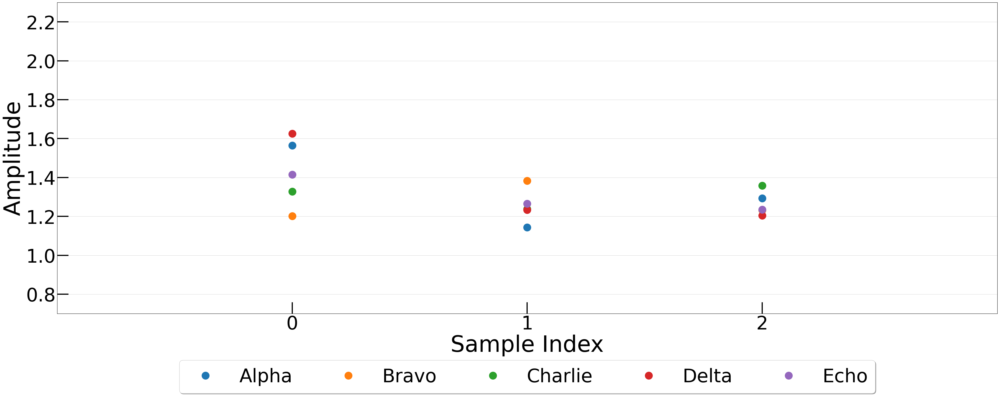

In [24]:
S_alpha = Alpha_Yellow_MP[test_loc]
S_bravo = Bravo_Yellow_MP[test_loc]
S_charlie = Charlie_Yellow_MP[test_loc]
S_delta = Delta_Yellow_MP[test_loc]
S_echo = Echo_Yellow_MP[test_loc]

Shape = S_alpha.shape[0]
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
plt.plot(np.arange(S_alpha.shape[0]), S_alpha, "o", label="Alpha", markersize=20)
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, "o", label="Bravo", markersize=20)
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, "o", label="Charlie", markersize=20)
plt.plot(np.arange(S_delta.shape[0]), S_delta, "o", label="Delta", markersize=20)
plt.plot(np.arange(S_echo.shape[0]), S_echo, "o", label="Echo", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(S_alpha)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(S_alpha)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.savefig(save_folder + "Yellow_MPs.png", bbox_inches='tight')
plt.show()
plt.close()

## Red

In [25]:
S_bravo 

array([1.20219126, 1.38247224, 1.23223798])

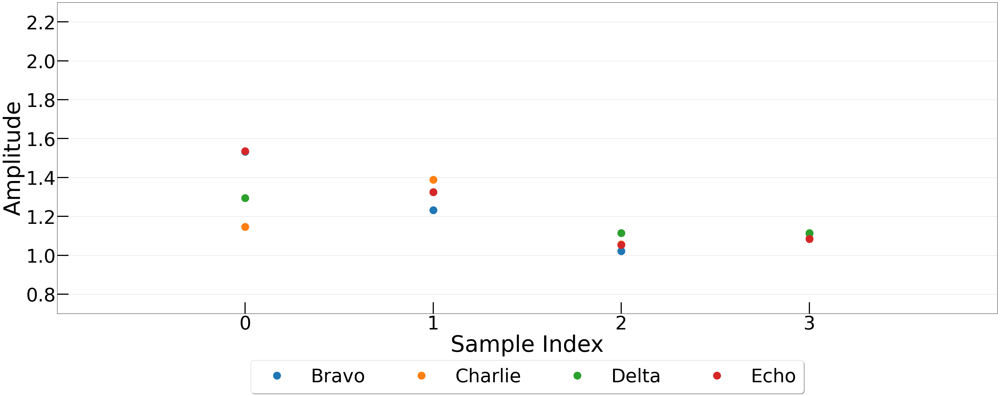

In [26]:
#S_alpha = Alpha_Red_MP[test_loc]
S_bravo = Bravo_Red_MP[test_loc]
S_charlie = Charlie_Red_MP[test_loc]
S_delta = Delta_Red_MP[test_loc]
S_echo = Echo_Red_MP[test_loc]

Shape = 0
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
#plt.plot(np.arange(S_alpha.shape[0]), S_alpha, "o", label="Alpha", markersize=20)
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, "o", label="Bravo", markersize=20)
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, "o", label="Charlie", markersize=20)
plt.plot(np.arange(S_delta.shape[0]), S_delta, "o", label="Delta", markersize=20)
plt.plot(np.arange(S_echo.shape[0]), S_echo, "o", label="Echo", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(S_bravo)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(S_bravo)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.savefig(save_folder + "Red_MPs.png", bbox_inches='tight')
plt.show()
plt.close()

## Orange

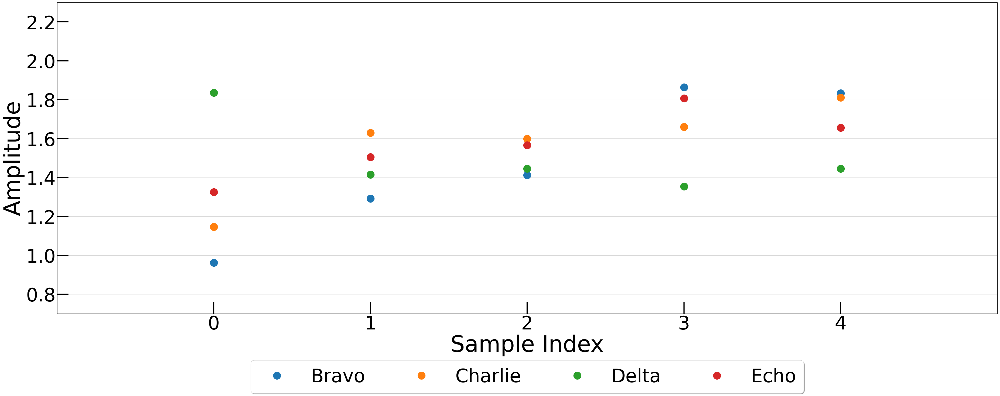

In [27]:
#S_alpha = Alpha_Orange_MP[test_loc]
S_bravo = Bravo_Orange_MP[test_loc]
S_charlie = Charlie_Orange_MP[test_loc]
S_delta = Delta_Orange_MP[test_loc]
S_echo = Echo_Orange_MP[test_loc]

Shape = 0
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
#plt.plot(np.arange(S_alpha.shape[0]), S_alpha, "o", label="Alpha", markersize=20)
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, "o", label="Bravo", markersize=20)
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, "o", label="Charlie", markersize=20)
plt.plot(np.arange(S_delta.shape[0]), S_delta, "o", label="Delta", markersize=20)
plt.plot(np.arange(S_echo.shape[0]), S_echo, "o", label="Echo", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(S_bravo)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(S_bravo)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.savefig(save_folder + "Orange_MPs.png", bbox_inches='tight')
plt.show()
plt.close()

## Green

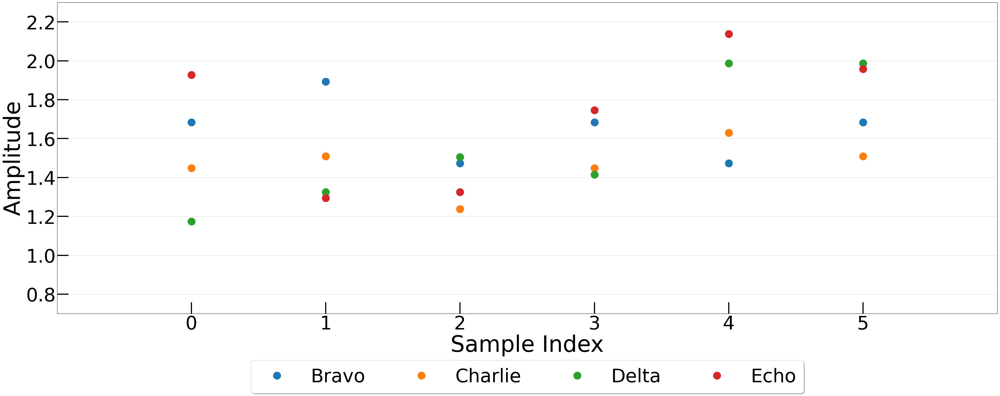

In [28]:
#S_alpha = Alpha_Green_MP[test_loc]
S_bravo = Bravo_Green_MP[test_loc]
S_charlie = Charlie_Green_MP[test_loc]
S_delta = Delta_Green_MP[test_loc]
S_echo = Echo_Green_MP[test_loc]

Shape = 0
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
#plt.plot(np.arange(S_alpha.shape[0]), S_alpha, "o", label="Alpha", markersize=20)
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, "o", label="Bravo", markersize=20)
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, "o", label="Charlie", markersize=20)
plt.plot(np.arange(S_delta.shape[0]), S_delta, "o", label="Delta", markersize=20)
plt.plot(np.arange(S_echo.shape[0]), S_echo, "o", label="Echo", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(S_bravo)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(S_bravo)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.savefig(save_folder + "Green_MPs.png", bbox_inches='tight')
plt.show()
plt.close()

## Blue

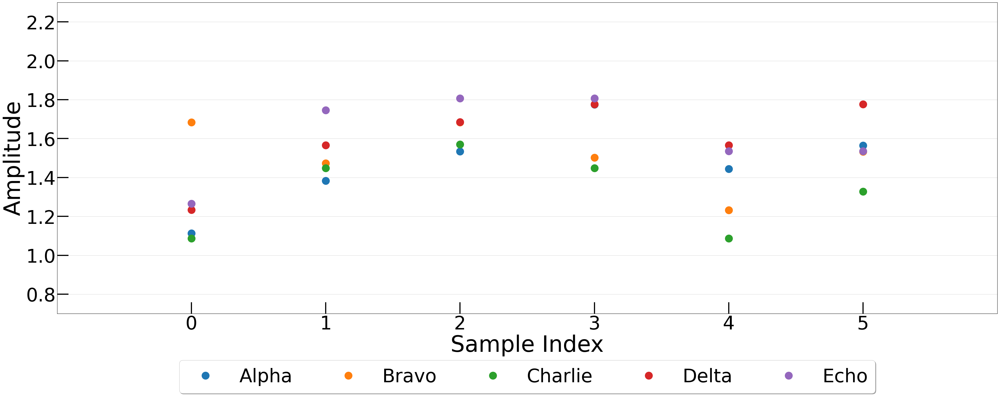

In [29]:
S_alpha = Alpha_Blue_MP[test_loc]
S_bravo = Bravo_Blue_MP[test_loc]
S_charlie = Charlie_Blue_MP[test_loc]
S_delta = Delta_Blue_MP[test_loc]
S_echo = Echo_Blue_MP[test_loc]

Shape = S_alpha.shape[0]
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
plt.plot(np.arange(S_alpha.shape[0]), S_alpha, "o", label="Alpha", markersize=20)
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, "o", label="Bravo", markersize=20)
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, "o", label="Charlie", markersize=20)
plt.plot(np.arange(S_delta.shape[0]), S_delta, "o", label="Delta", markersize=20)
plt.plot(np.arange(S_echo.shape[0]), S_echo, "o", label="Echo", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(S_alpha)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(S_alpha)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.savefig(save_folder + "Blue_MPs.png", bbox_inches='tight')
plt.show()
plt.close()

## Brown

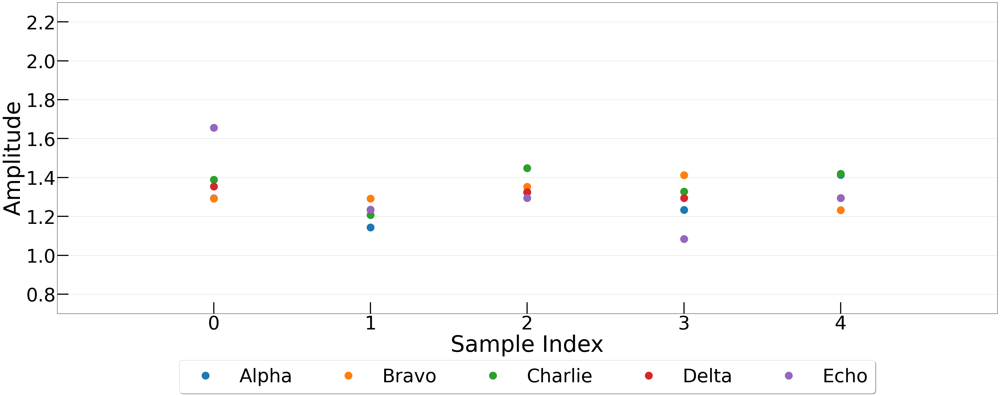

In [30]:
S_alpha = Alpha_Brown_MP[test_loc]
S_bravo = Bravo_Brown_MP[test_loc]
S_charlie = Charlie_Brown_MP[test_loc]
S_delta = Delta_Brown_MP[test_loc]
S_echo = Echo_Brown_MP[test_loc]

Shape = S_alpha.shape[0]
if S_bravo.shape[0] > Shape:
    Shape = S_bravo.shape[0]
if S_charlie.shape[0] > Shape:
    Shape = S_charlie.shape[0]
if S_delta.shape[0] > Shape:
    Shape = S_delta.shape[0]
if S_echo.shape[0] > Shape:
    Shape = S_echo.shape[0]


time_Signal = np.arange(Shape)
plt.plot(np.arange(S_alpha.shape[0]), S_alpha, "o", label="Alpha", markersize=20)
plt.plot(np.arange(S_bravo.shape[0]), S_bravo, "o", label="Bravo", markersize=20)
plt.plot(np.arange(S_charlie.shape[0]), S_charlie, "o", label="Charlie", markersize=20)
plt.plot(np.arange(S_delta.shape[0]), S_delta, "o", label="Delta", markersize=20)
plt.plot(np.arange(S_echo.shape[0]), S_echo, "o", label="Echo", markersize=20)
#MapTool.mapCodeSignal(Signal, code, pad)
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(axis='y')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          fancybox=True, shadow=True, ncol=6)
plt.xlim([-1,len(S_alpha)])
plt.ylim(0.7,2.3)
plt.xticks(np.arange(len(S_alpha)))
plt.tick_params(direction='in', length=30, width=3, grid_alpha=0.5)
plt.savefig(save_folder + "Brown_MPs.png", bbox_inches='tight')
plt.show()
plt.close()

# BoxPlot Comparison of instructions

In [31]:
'''
Creates a box plot comparing multiple samples with the two instructions found inside the samples by getting the range of the 
peak values for the two singals for each sample.

list_signals: an np array containing the [sample_name, samples, first_inst, second_inst, first_code_name, second_code_name] for each sample set.
start_Peak: The starting segement peak of interest.
end_Peak: The ending segment peak range of interest.
'''
def boxPlotComparison(list_signals, start_Peak, end_Peak, y_low=0.90, y_high=1.2, folder=""):
    dictionary = []
    
    change_Values = []

    # Get the sample set. I.E. [sample_name, samples, first_inst, second_inst, first_code_name, second_code_name] 
    for s in range(len(list_signals)):
        # Get the peak values
        samples_Seg = pC.getSeqSignals(list_signals[s][1], start_Peak, end_Peak, pad)
        peaks = MapTool.getPeaksDataset(samples_Seg,pad)
        
        # Create the dictionary for the box plot.
        if list_signals[s][4] == "" and list_signals[s][5] == "":
            dictionary.append([np.array(peaks[:,0]), list_signals[s][2]])
            dictionary.append([np.array(peaks[:,2]), list_signals[s][3]])
        else:
            dictionary.append([np.array(peaks[:,0]), list_signals[s][4]])
            dictionary.append([np.array(peaks[:,2]), list_signals[s][5]])
        
    # Create the box plot.
    if folder != "":
        BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", 
                     y_low, y_high, pad, folder=folder)
    else:
        BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", 
                     y_low, y_high, pad)

In [32]:
# Box plot
params = {'legend.fontsize': 50,
          'figure.figsize': (75, 10),
         'axes.labelsize': 60,
         'axes.titlesize':70,
         'xtick.labelsize':30,
         'ytick.labelsize':30,
         'lines.linewidth': 5}
plt.rcParams.update(params)

In [33]:
y_low = 0.8
y_high= 3

# Yellow

(3000,)


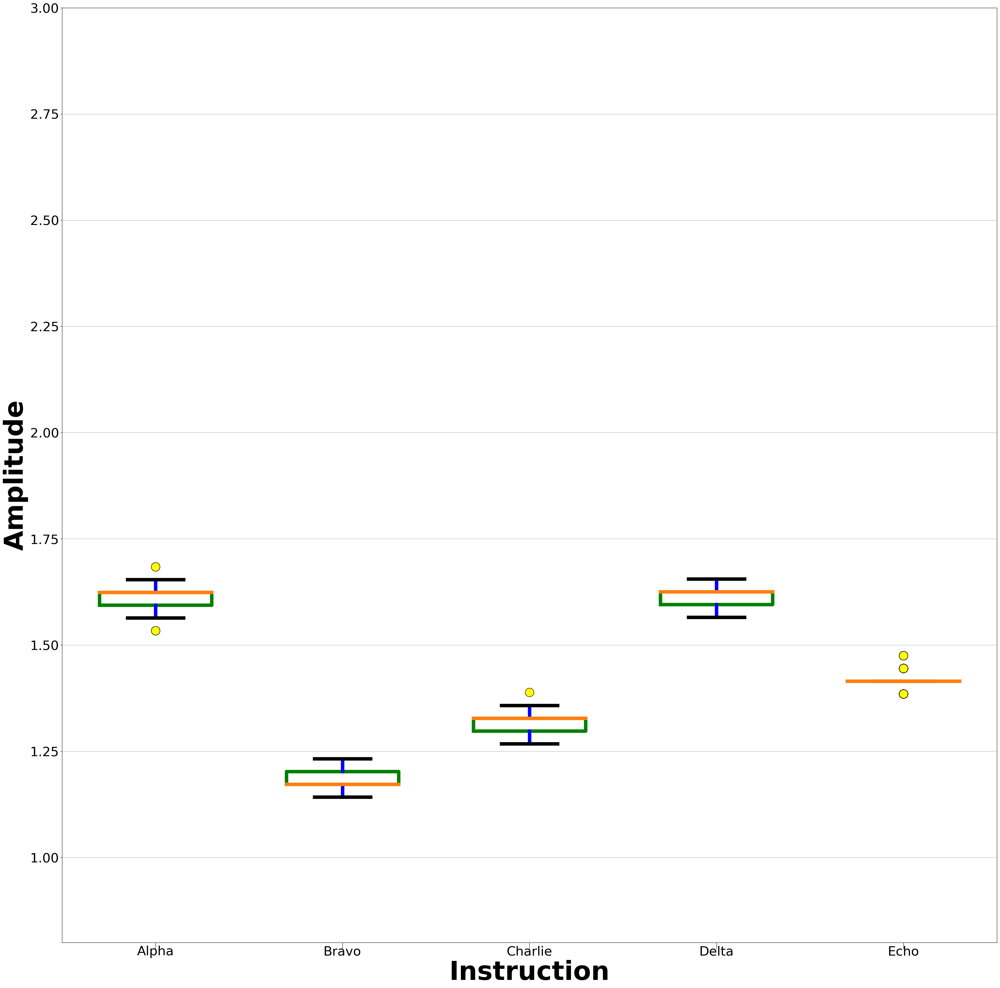

In [34]:
increment = 0
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),46+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),10+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),6+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),22+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Yellow_ori_1.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


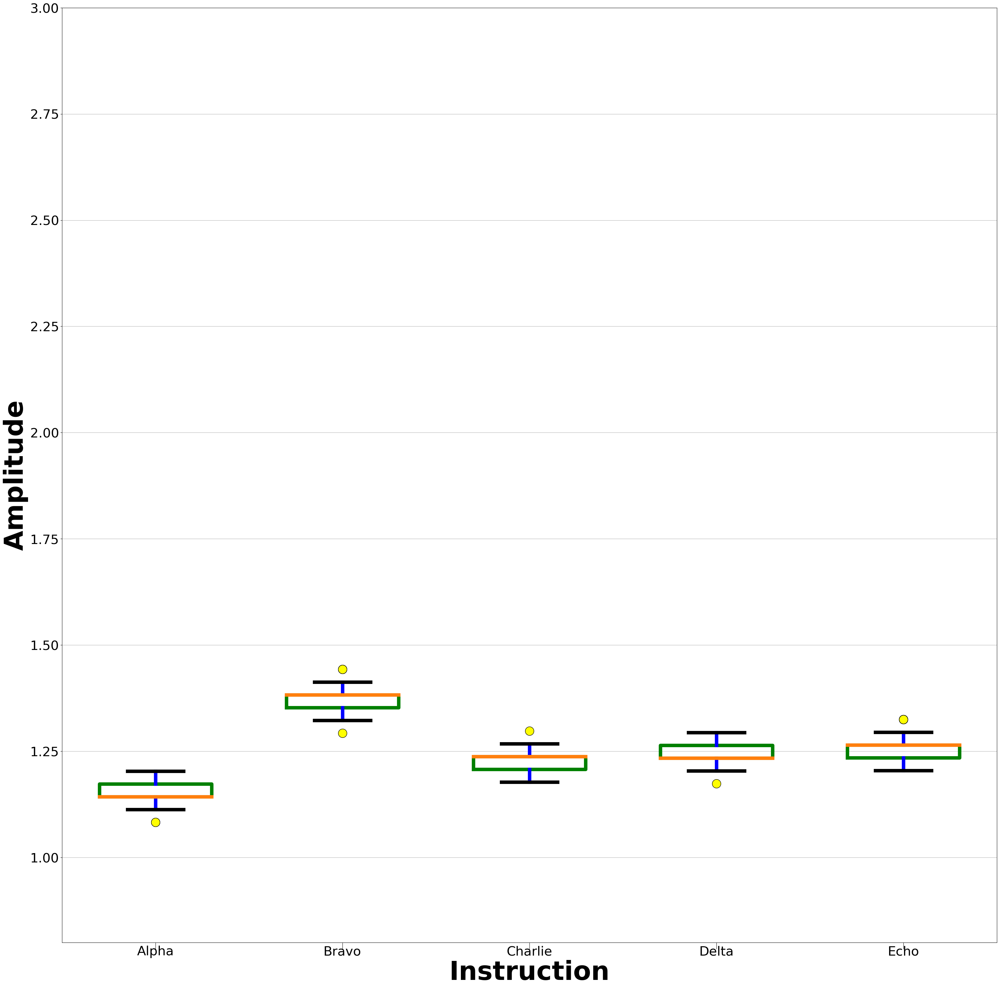

In [35]:
increment = 1
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),46+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),10+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),6+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),22+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Yellow_mov_2.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


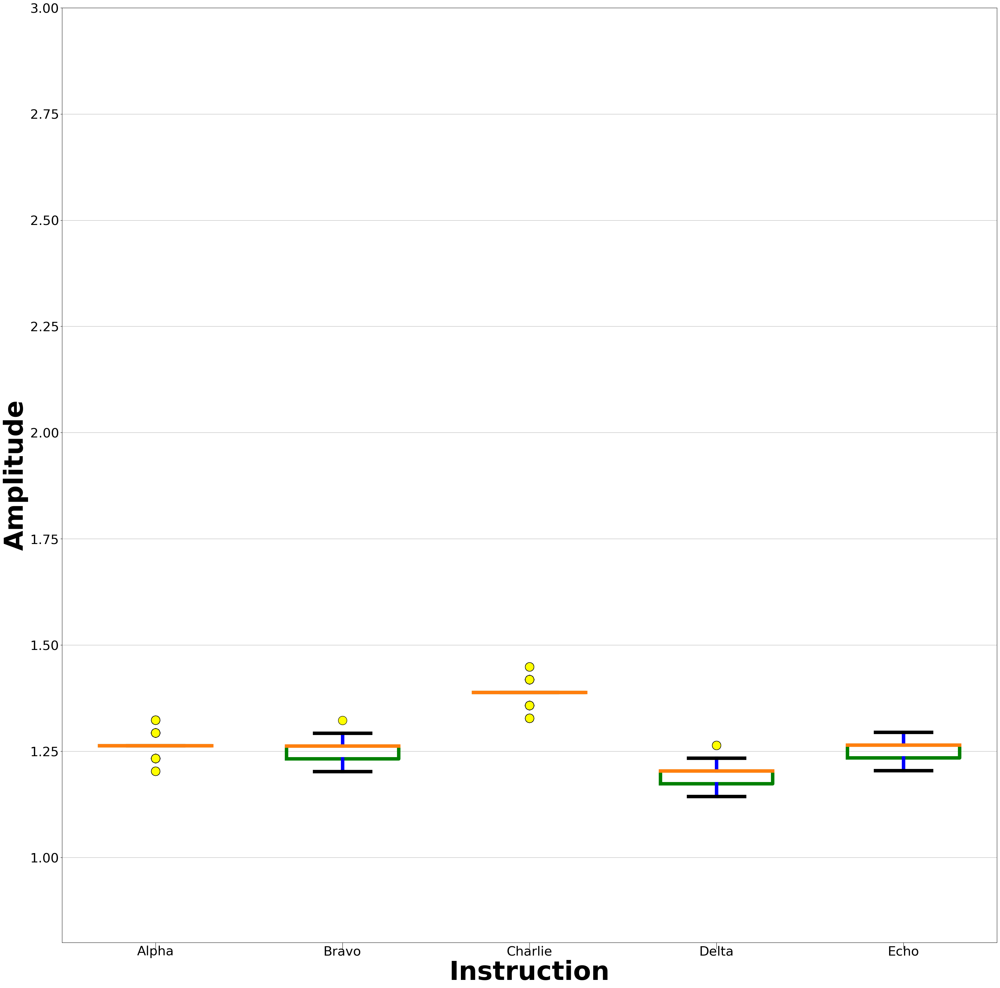

In [36]:
increment = 2
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),46+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),10+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),6+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),22+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Yellow_andi_3.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

# Red

(3000,)


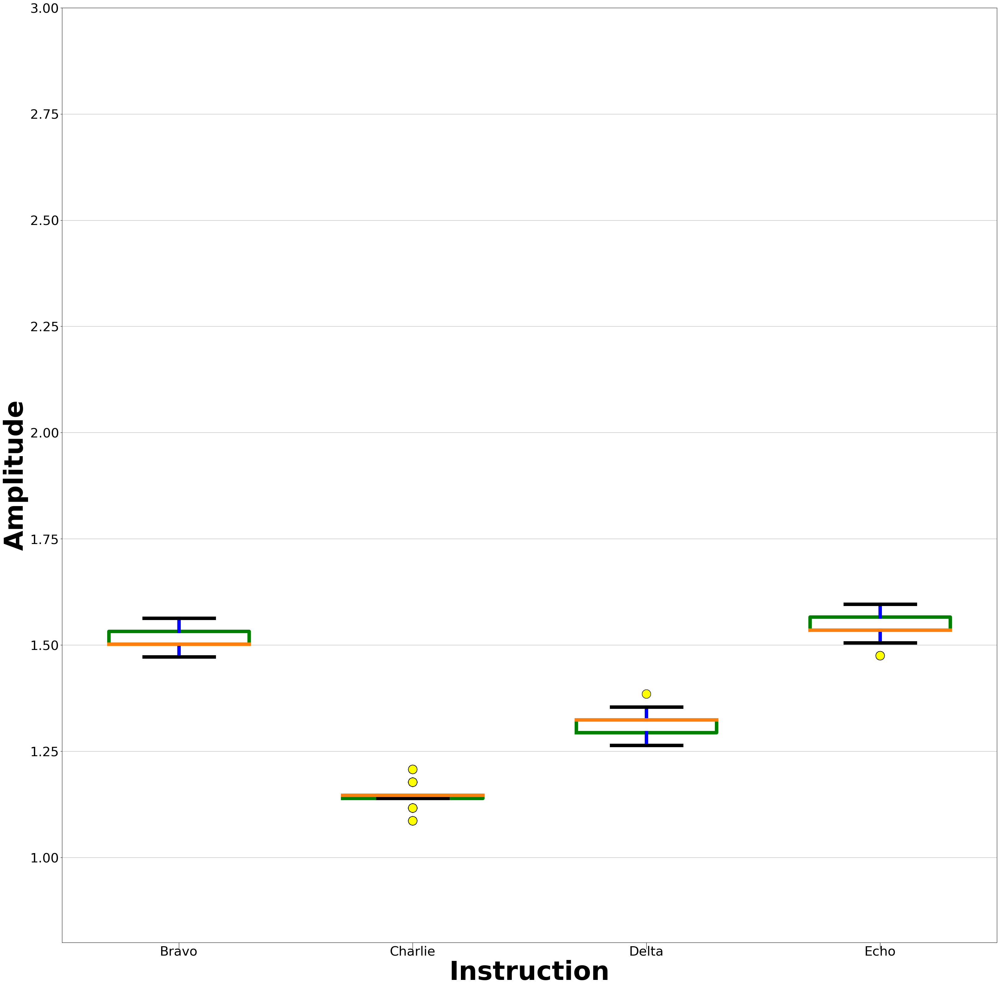

In [37]:
increment = 0
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),26+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),66+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),64+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),6+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Red_ori_1.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


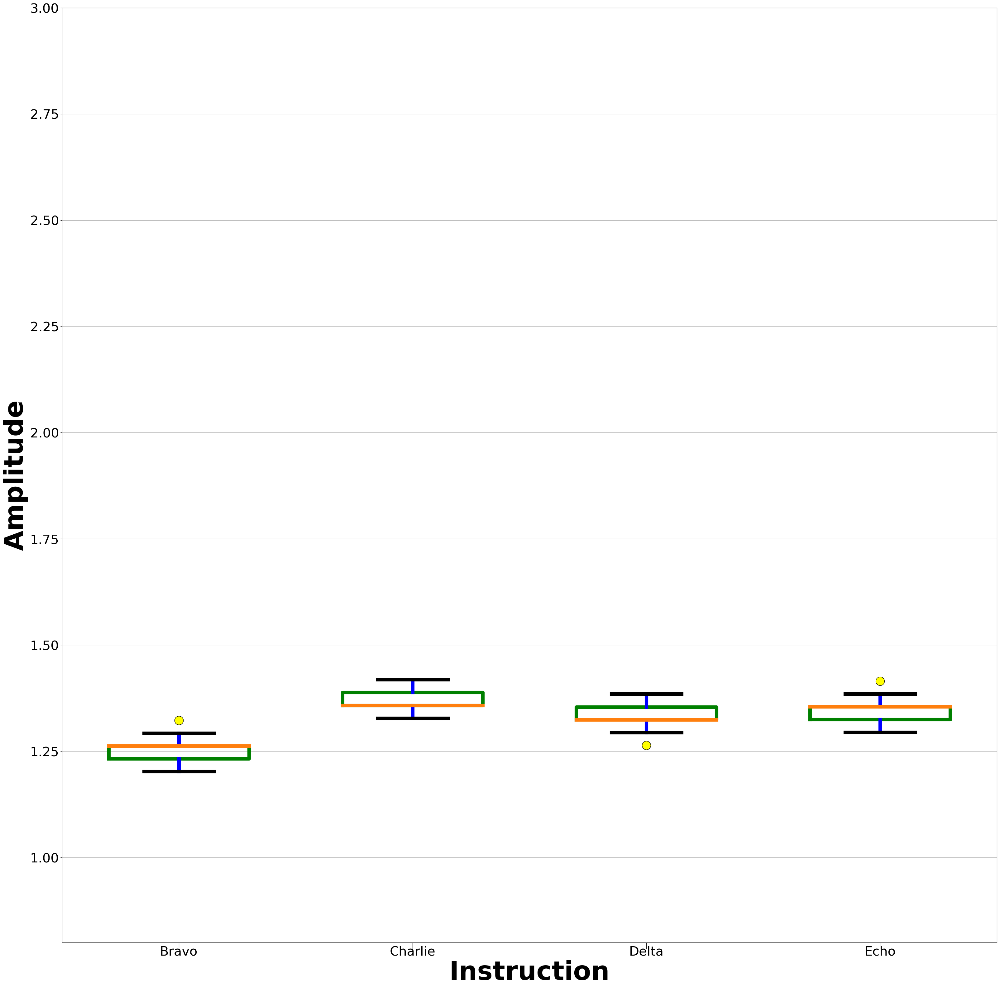

In [38]:
increment = 1
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),26+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),66+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),64+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),6+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Red_muls_2.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


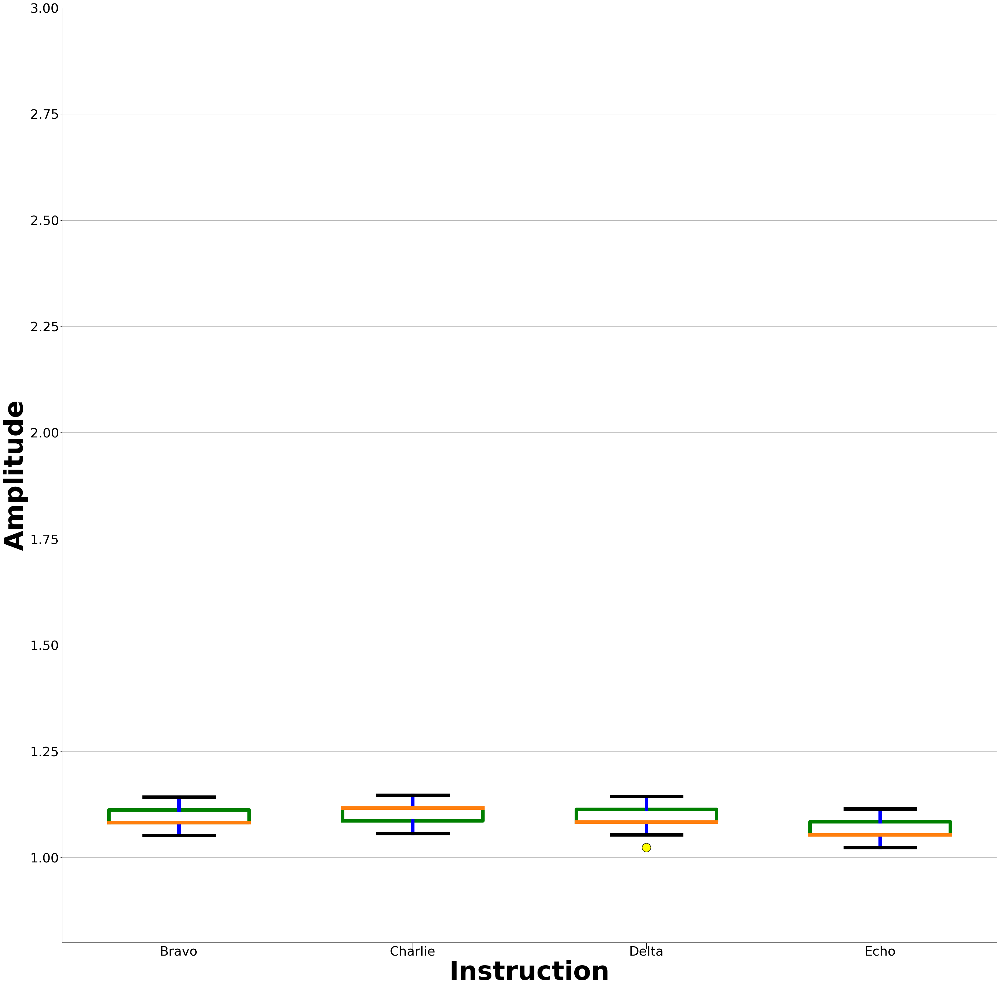

In [39]:
increment = 3
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),26+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),66+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),64+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),6+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Red_nop_3.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

# Orange

(3000,)


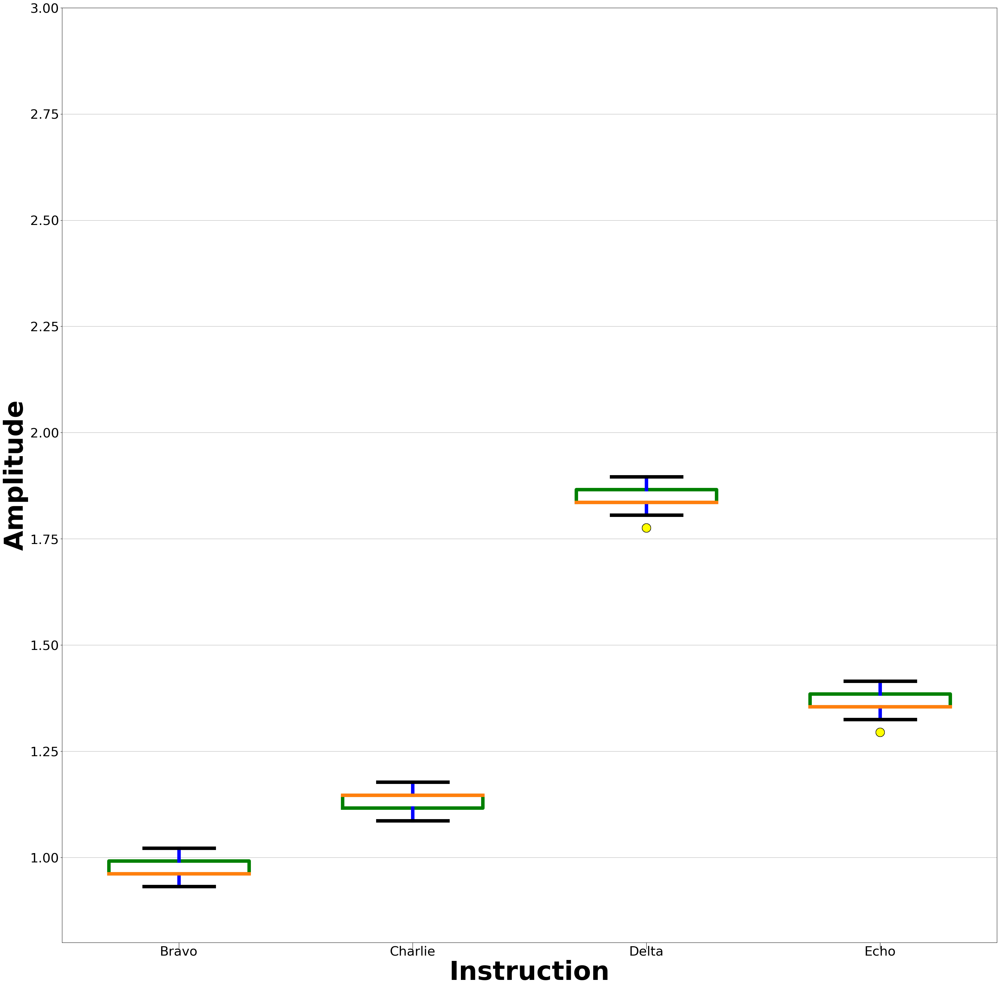

In [40]:
increment = 0
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),0+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),40+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),50+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),122+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Orange_lds_1.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


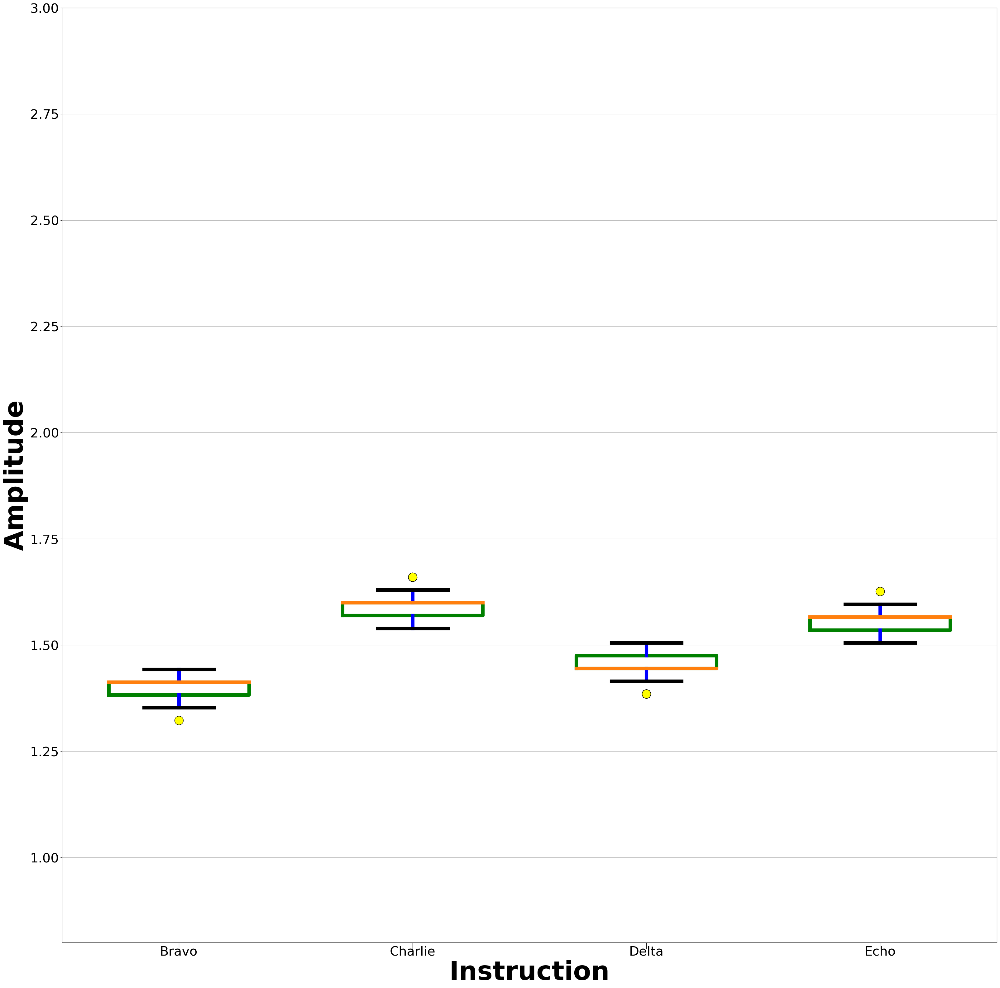

In [41]:
increment = 2
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),0+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),40+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),50+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),122+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Orange_ori_2.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


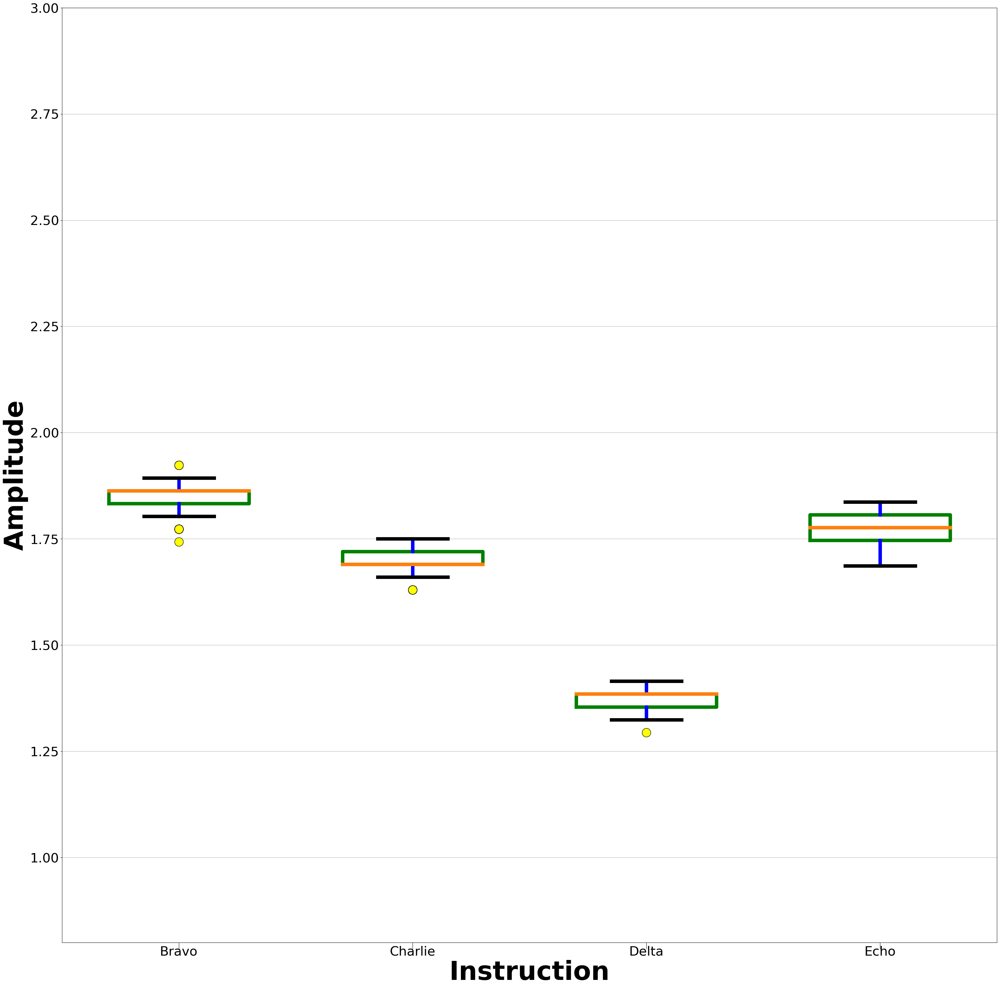

In [42]:
increment = 3
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),10+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),0+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),40+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),50+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),122+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Orange_sts_3.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

# Blue

(3000,)


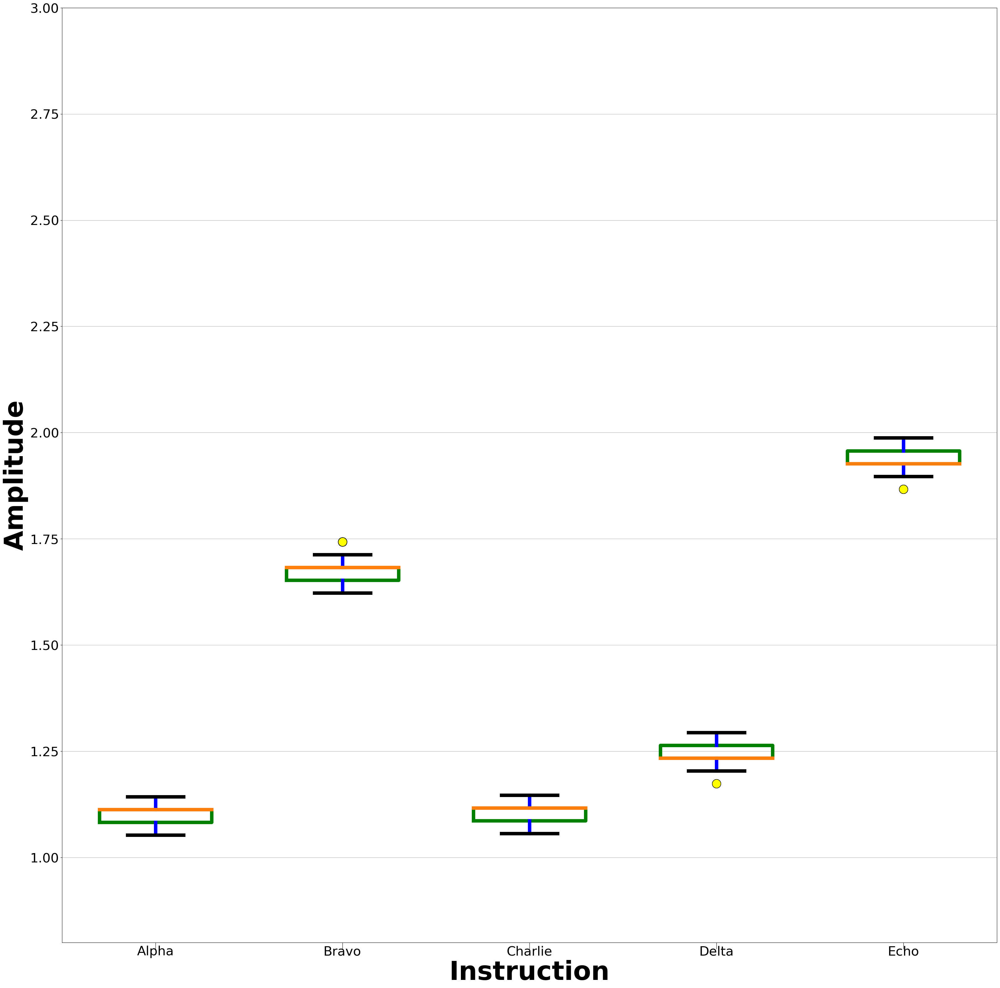

In [43]:
increment = 0
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),16+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),0+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),88+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),40+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Blue_ori_1.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


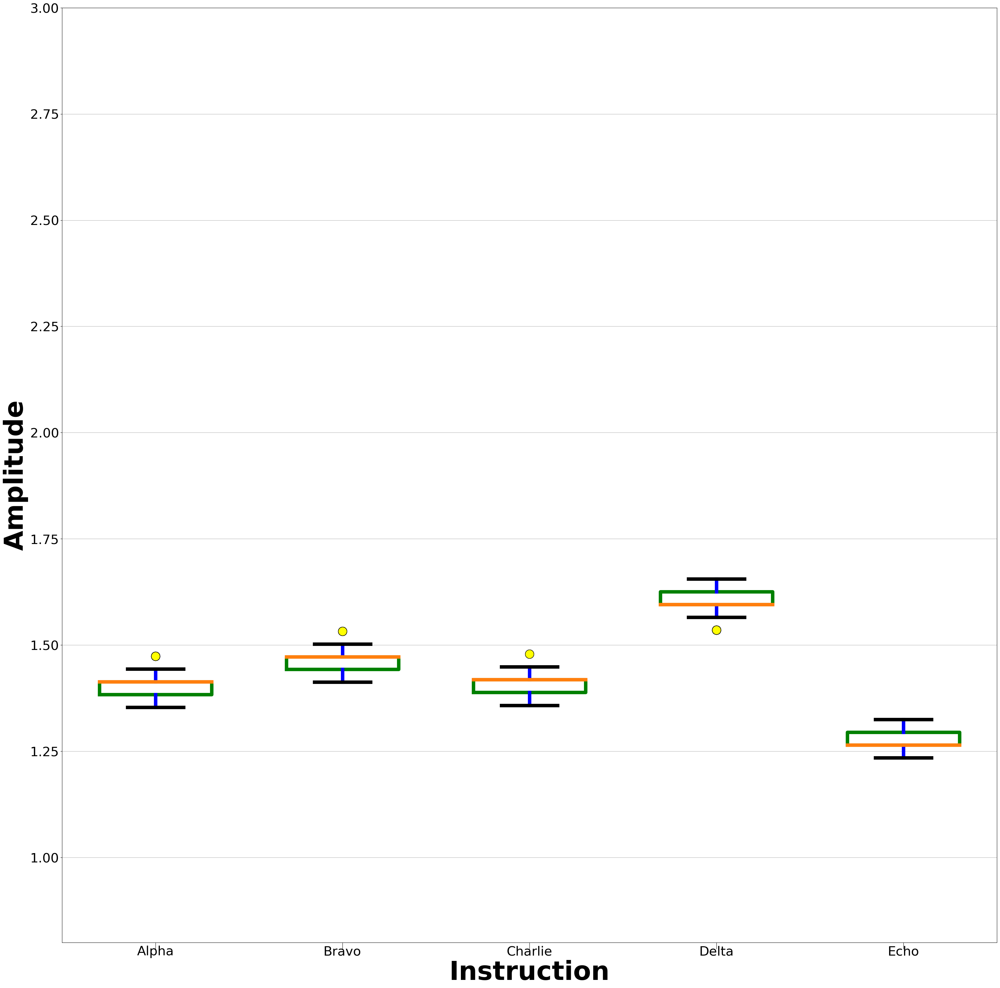

In [44]:
increment = 1
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),16+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),0+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),88+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),40+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Blue_sts_2.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


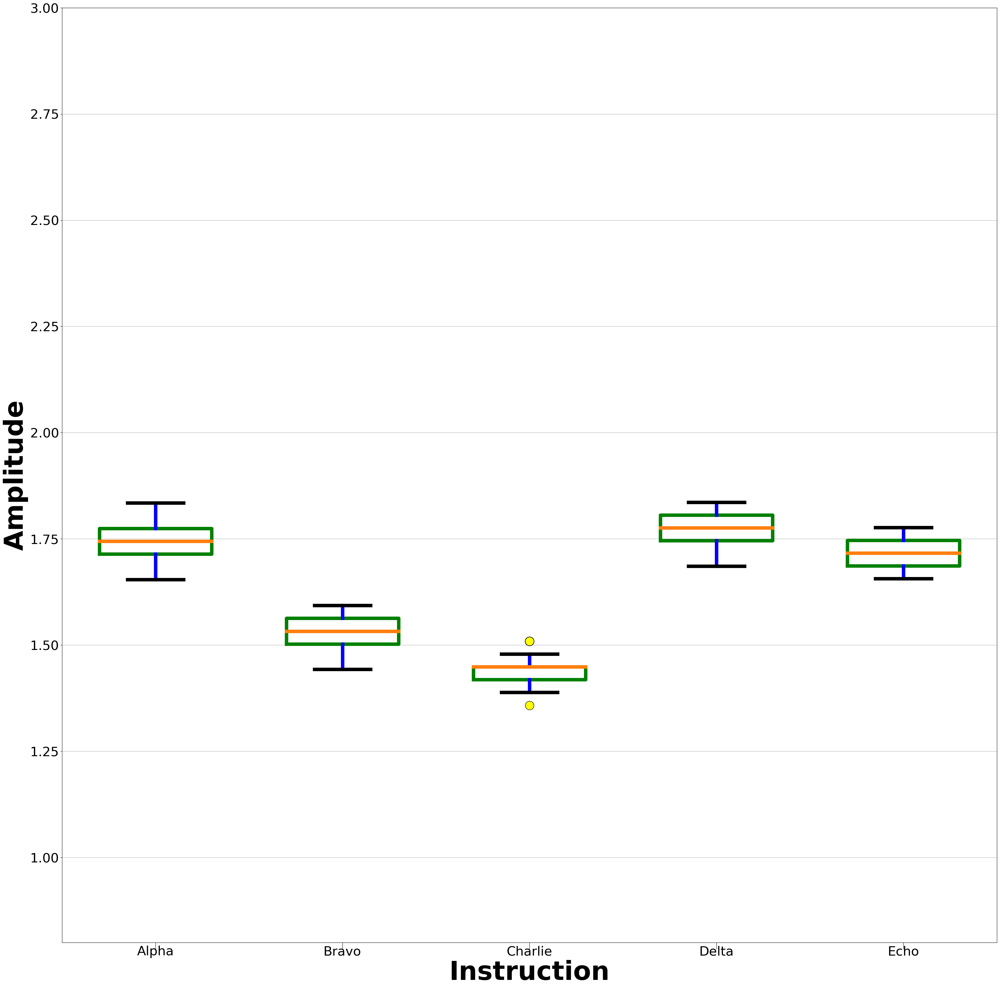

In [45]:
increment = 3
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),16+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),0+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),88+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),40+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Blue_lds_3.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


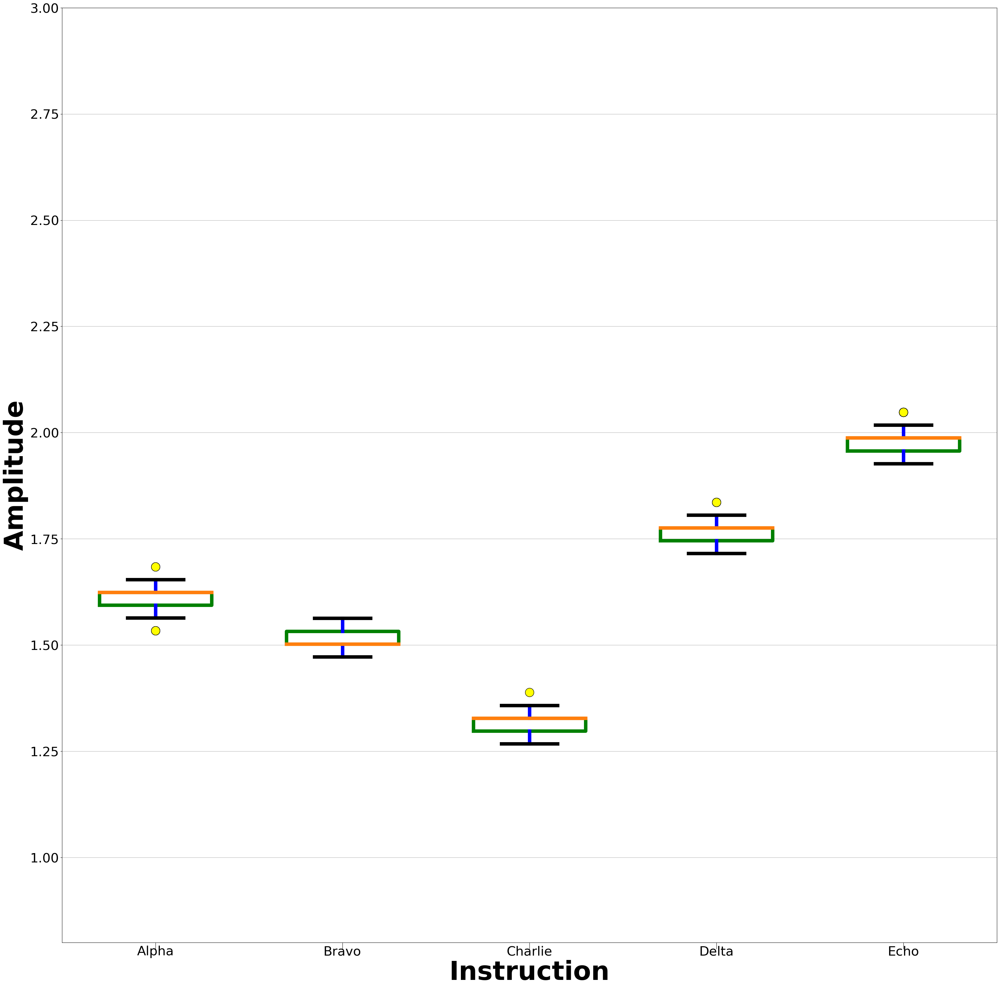

In [46]:
increment = 5
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),16+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),0+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),88+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),40+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Blue_ori_4.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

# Green

(3000,)


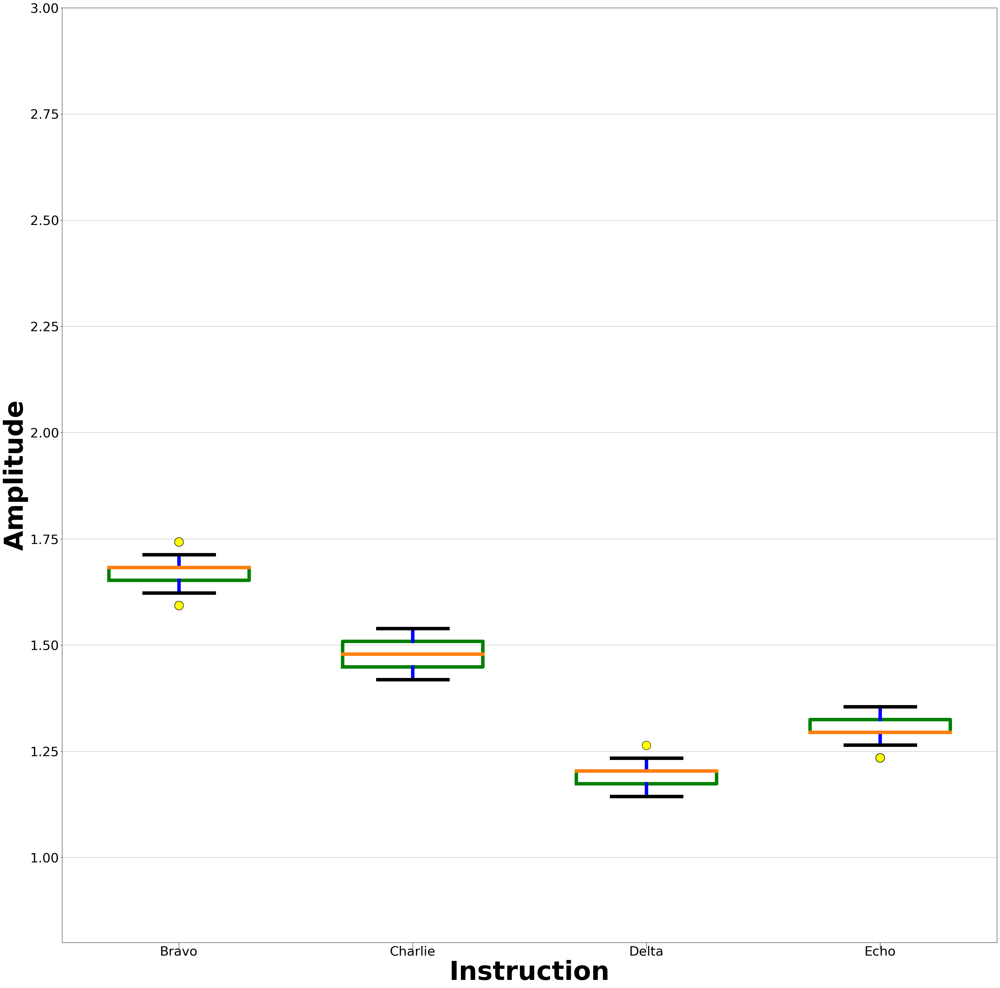

In [47]:
increment = 0
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),10+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),22+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),72+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),58+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Green_out_1.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


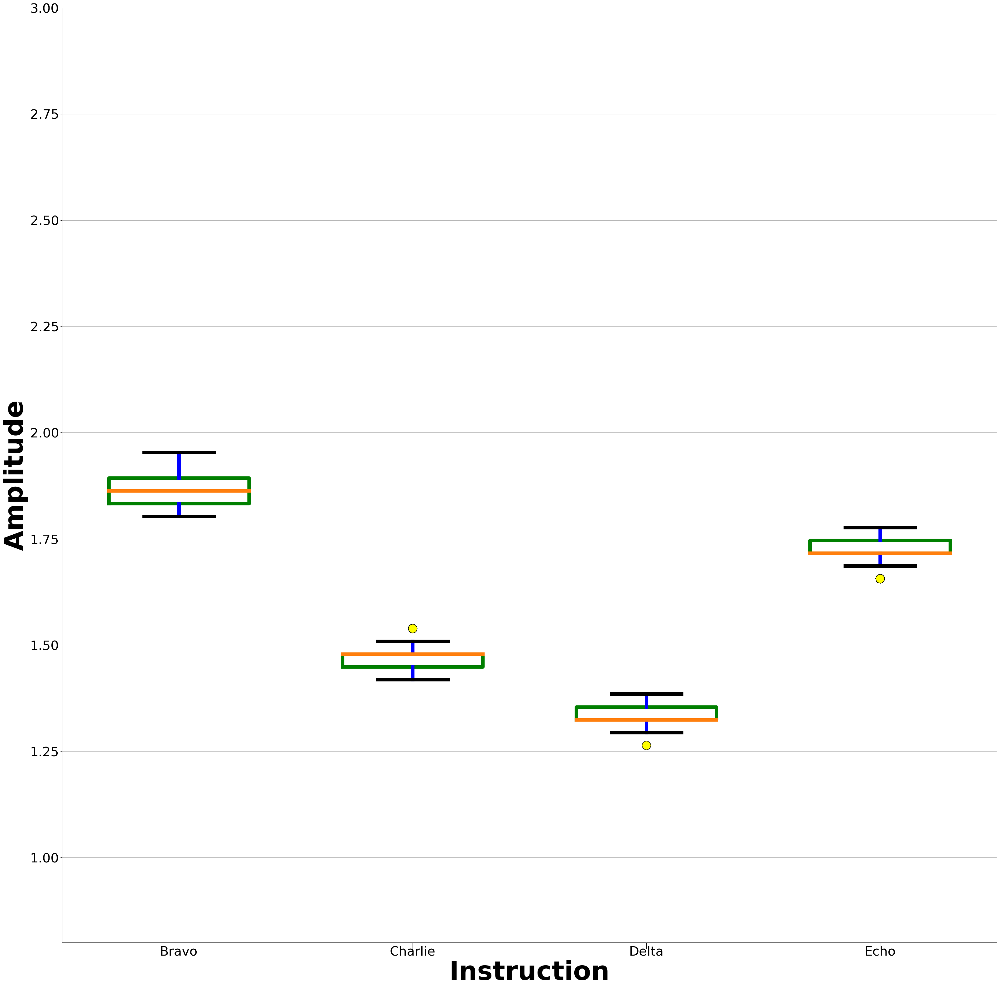

In [48]:
increment = 1
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),10+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),22+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),72+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),58+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Green_lds_2.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


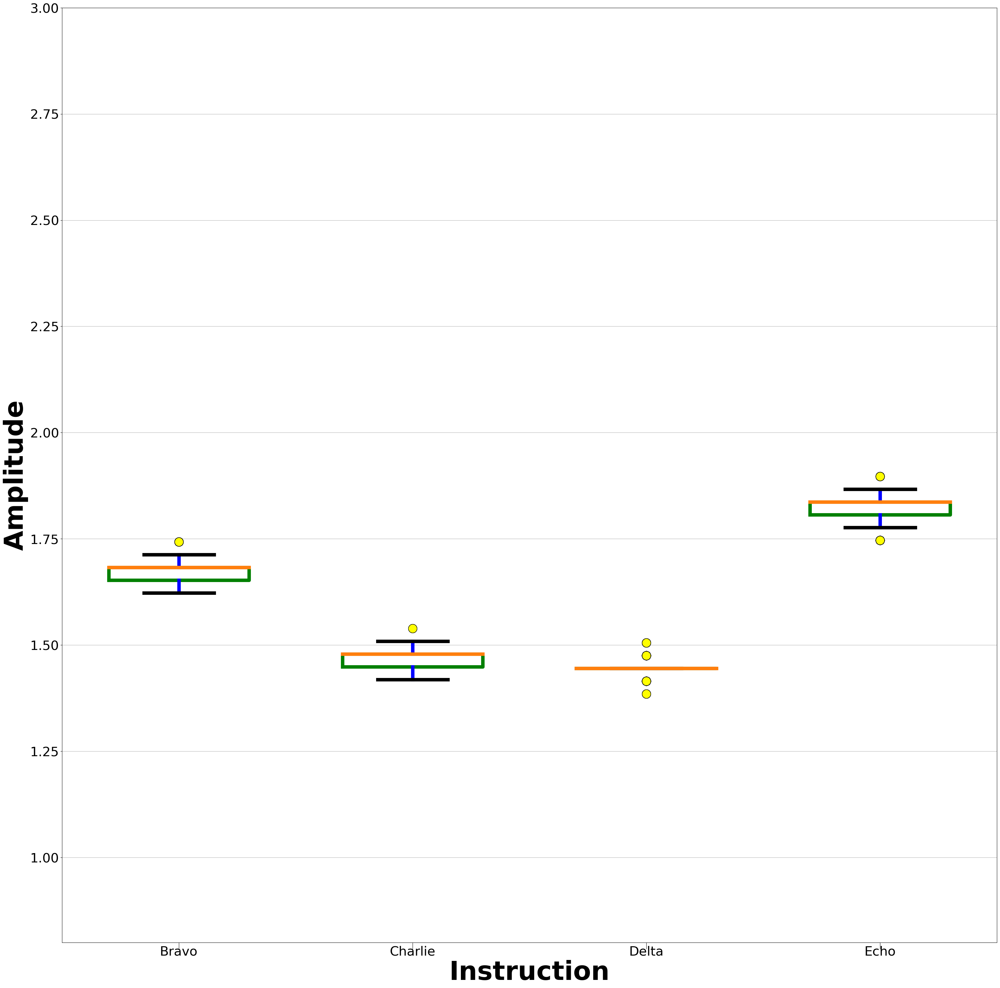

In [49]:
increment = 3
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),10+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),22+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),72+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),58+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Green_ori_3.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


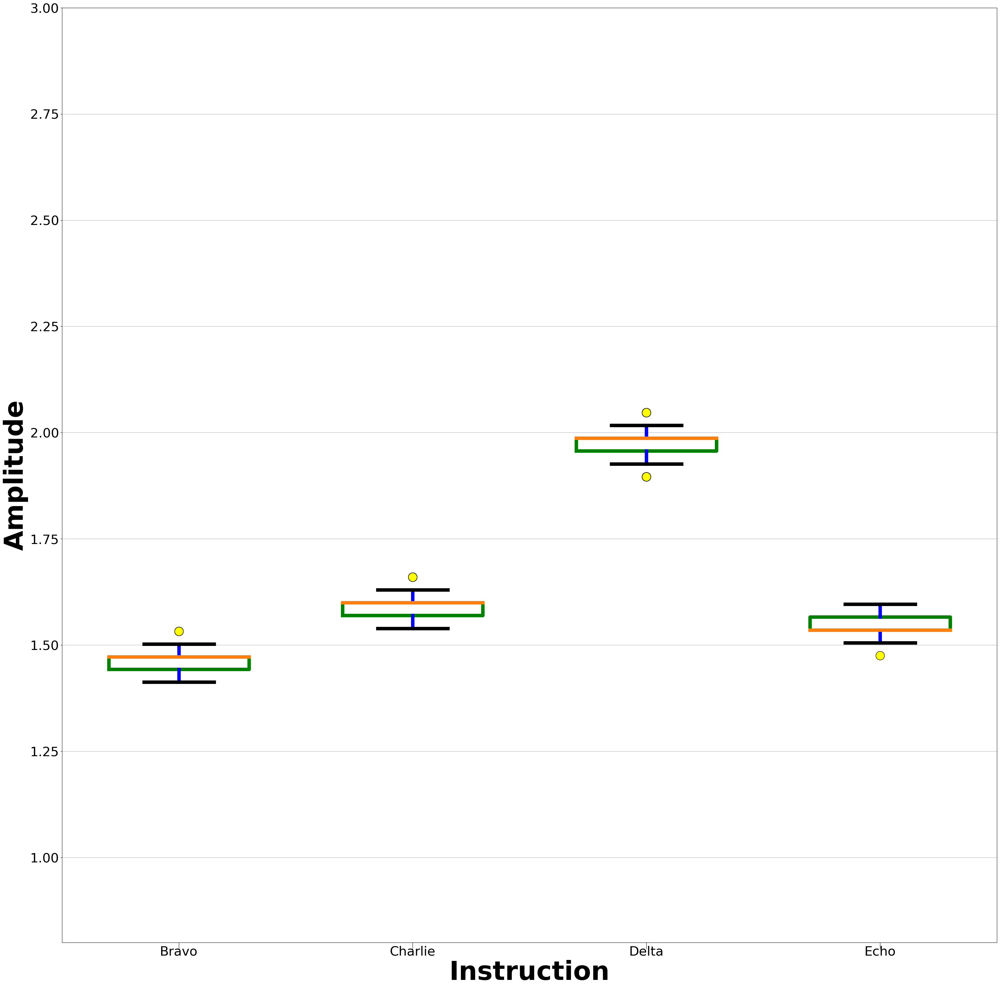

In [50]:
increment = 4
add_loc = increment * 2
#dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),0+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),10+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),22+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),72+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),58+add_loc), "Echo"]

dictionary = [dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Green_sts_4.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

# Brown

(3000,)


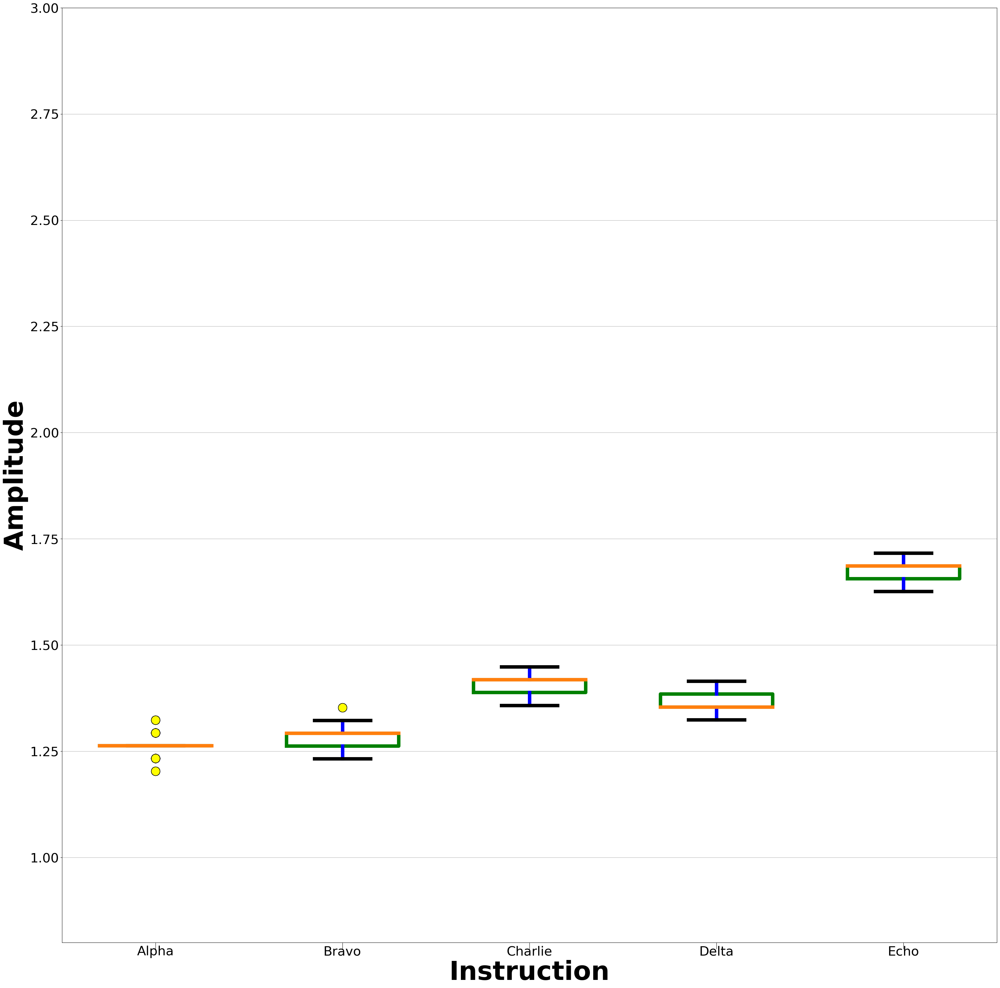

In [51]:
increment = 0
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),14+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),34+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),56+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),24+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),96+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Brown_andi_1.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


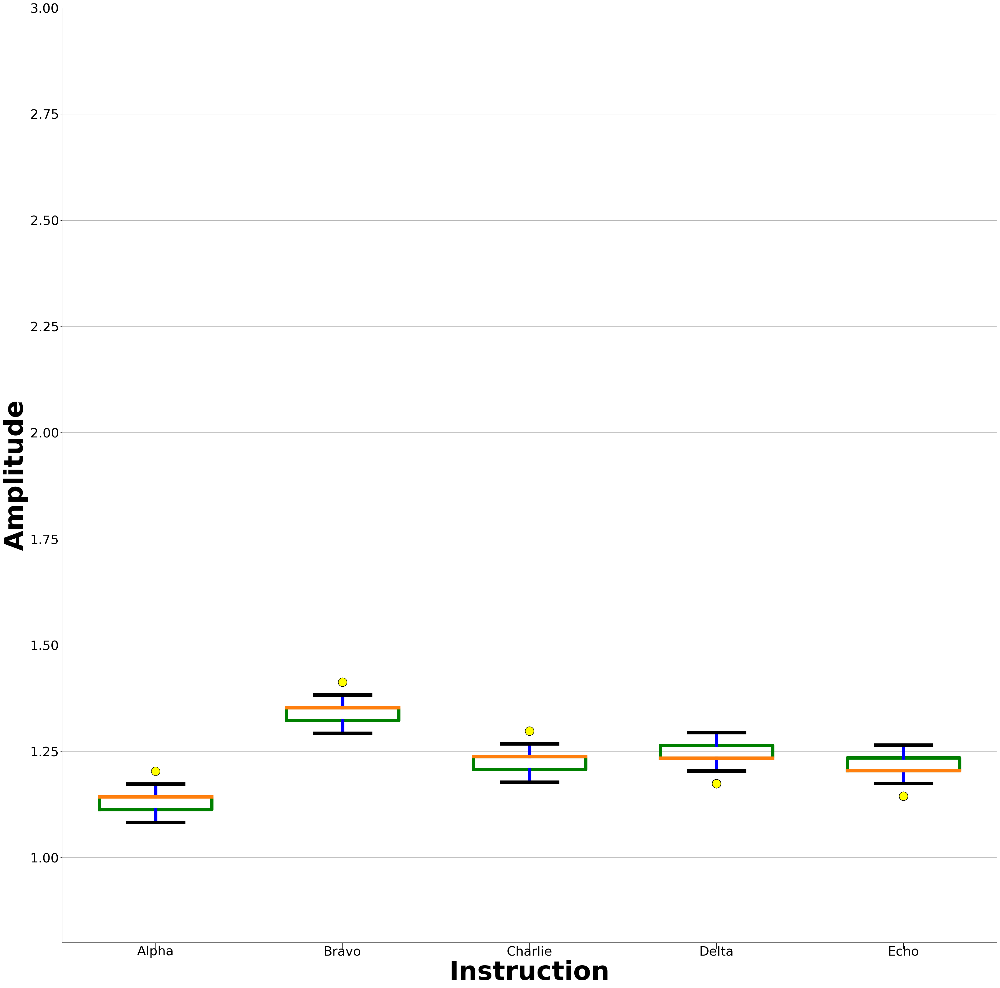

In [52]:
increment = 1
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),14+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),34+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),56+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),24+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),96+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Brown_mov_2.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


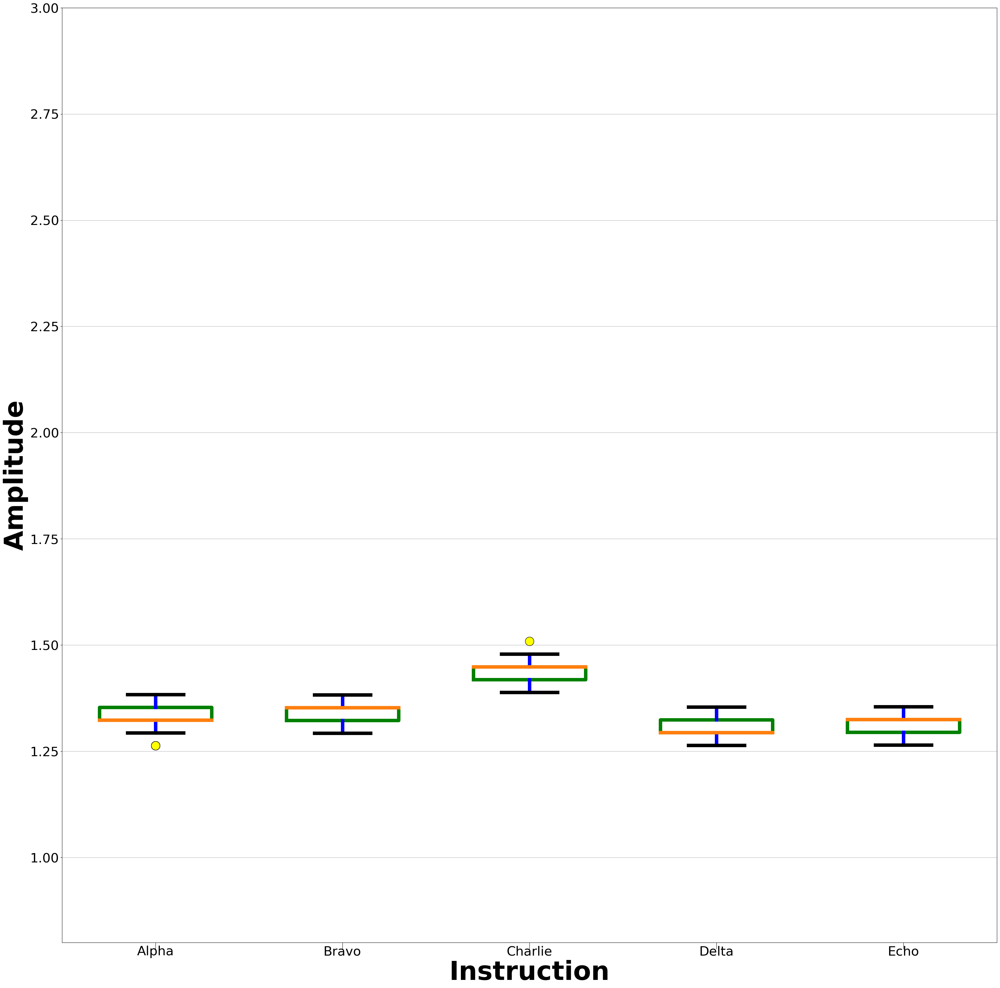

In [53]:
increment = 2
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),14+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),34+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),56+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),24+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),96+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Brown_ori_3.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


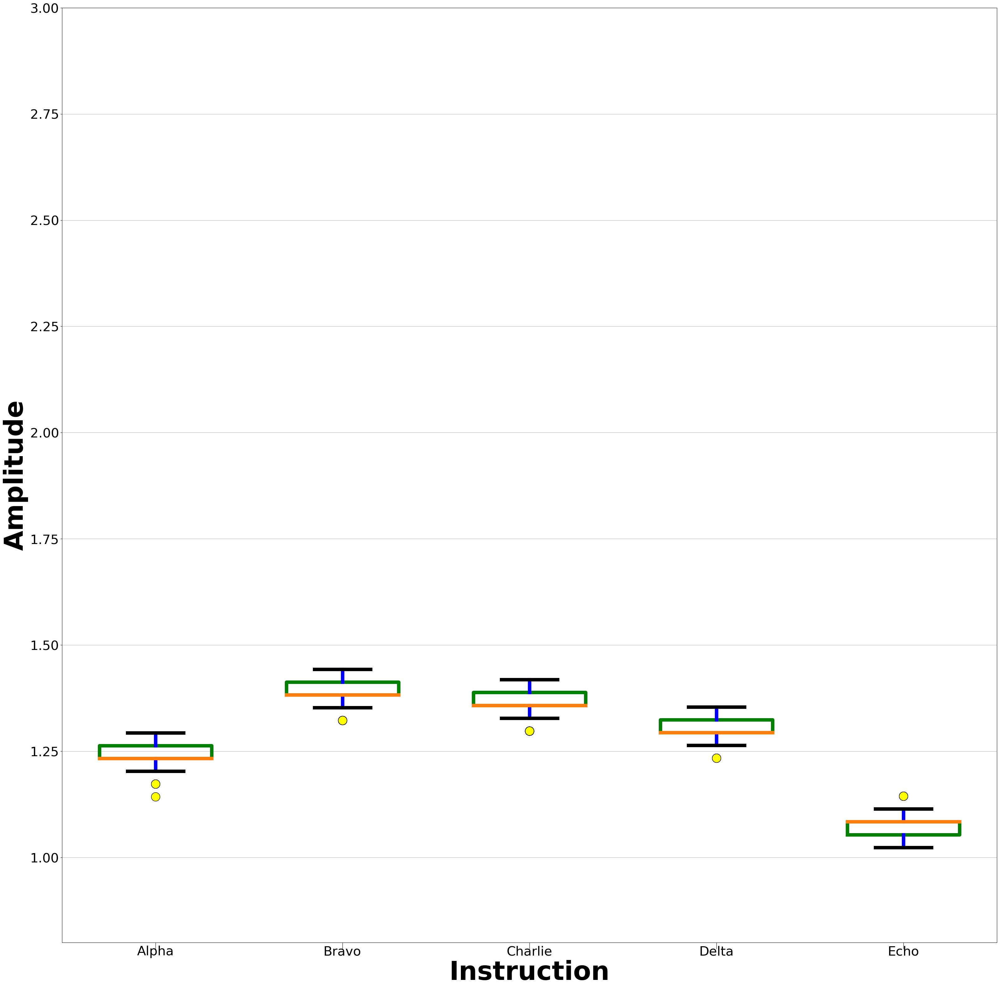

In [54]:
increment = 3
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),14+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),34+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),56+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),24+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),96+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Brown_mov_4.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)

(3000,)


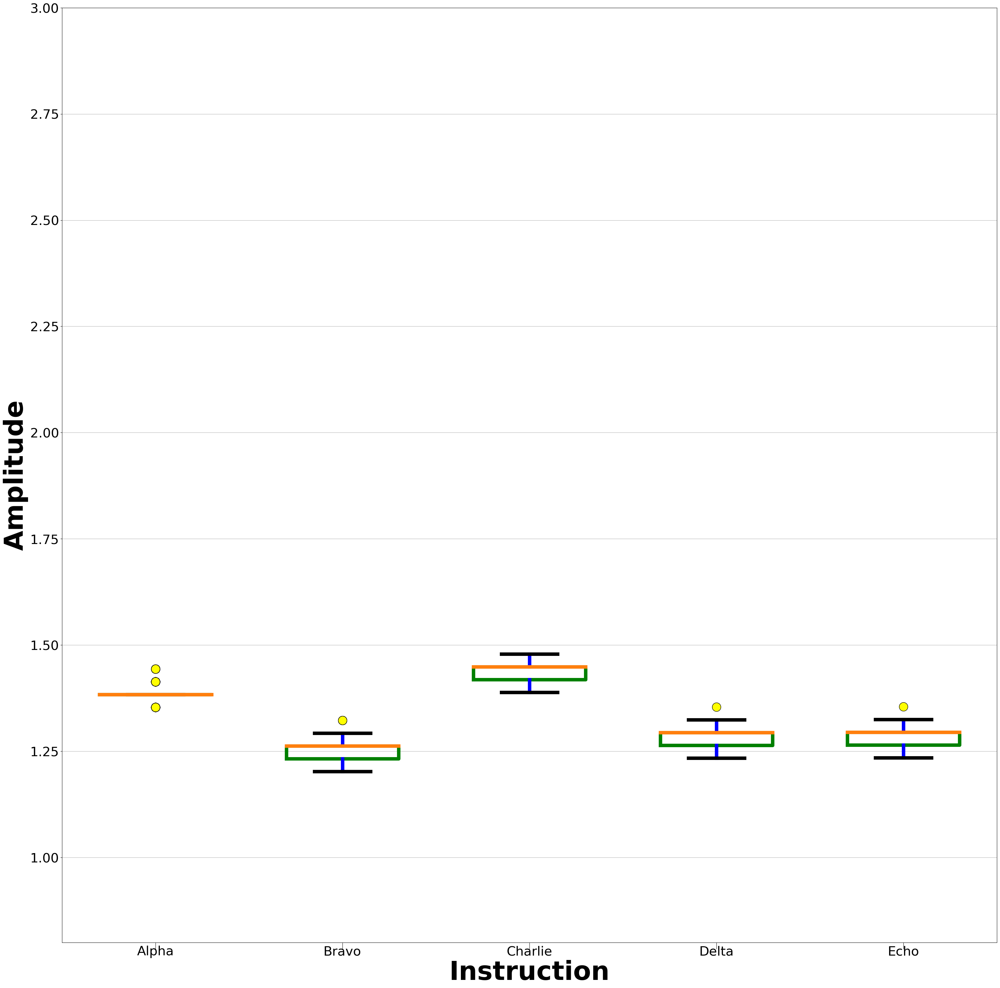

In [55]:
increment = 4
add_loc = increment * 2
dict_alpha = [getValue(MapTool.getPeaksDataset(Alpha,pad),14+add_loc), "Alpha"]
dict_bravo = [getValue(MapTool.getPeaksDataset(Bravo,pad),34+add_loc), "Bravo"]
dict_charlie = [getValue(MapTool.getPeaksDataset(Charlie,pad),56+add_loc), "Charlie"]
dict_delta = [getValue(MapTool.getPeaksDataset(Delta,pad),24+add_loc), "Delta"]
dict_echo = [getValue(MapTool.getPeaksDataset(Echo,pad),96+add_loc), "Echo"]

dictionary = [dict_alpha, dict_bravo, dict_charlie, dict_delta, dict_echo]

folder= save_folder + "BoxPlot_Amp_Brown_andi_5.png"
BoxPlot.boxPlotDataSeparate(dictionary, "Instruction", "Amplitude", "", y_low, y_high, pad, folder=folder)